# Coordination de satellites

### Etudiants :
- Jawher JRIBY 3702809
- Mélanie DELLUC 21104033

## 1 - Introduction

L'objectif de ce projet est d'étudier un problème d'allocation multi-agents de tâches dans lequel des tâches d’observations doivent être allouées à des constellations de satellites en orbite autour de la Terre.  

Nous nous appuyons, lors de ce projet, sur l’article “Auction-based and Distributed Optimization Approaches for Scheduling Observations in Satellite Constellations with Exclusive Orbit Portions, G. Picard, AAMAS ’22 : Proceedings of the 21st International Conference on Autonomous Agents and Multiagent Systems, May 2022”.  

Ainsi, à partir d’instances aléatoires, nous avons implémenté un DCOP, résolu par divers algorithmes provenant de la librairie pydcop. Ensuite, nous avons établi trois heuristiques d’enchères : PSI, SSI et enchères séquentielles basées sur le regret. Pour finir, nous avons comparé la qualité de solution et le temps de résolution de chacun de ces algorithmes. 

## 2 - Préparation : Instances et planification des tâches

In [ ]:
from typing import Callable, List, Set, Tuple, Dict
from matplotlib.patches import Rectangle
from collections import defaultdict
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import numpy as np
import subprocess
import random
import pydcop
import shlex
import time
import yaml
import math
import csv
import os
import re

### 2.1 - Générateur aléatoire

Dans un premier temps, nous allons implémenter un générateur aléatoire d'instances du problème EOSCSP à partir d'un nombre de satellites, d'utilisateurs exclusifs et de tâches. Pour cela, nous devons établir les structures de données nécessaires à la représentation du problème (EOSCSP, satellites, utilisateurs, requêtes, observations, solutions) et leurs contraintes associées avant de générer des instances de chaque élément.

#### 2.1.1 - Structures de données

##### 1. Problème EOSCSP

Un problème EOSCSP est défini par le tuple :

$$
P = (S, U, R, O)
$$

où :
- **S** : ensemble des satellites  
- **U** : ensemble des utilisateurs  
- **R** : ensemble des requêtes  
- **O** : ensemble des opportunités d’observation associées aux requêtes  

---

##### 2. Satellite

Un **satellite** est défini par le tuple :

$$
s =( t^{start}_s, t^{end}_s, \kappa_s, \tau_s)
$$

où :
- `t_start_s ∈ ℝ` : début du plan orbital  
- `t_end_s ∈ ℝ` : fin du plan orbital  
- `κ_s ∈ ℕ⁺` : capacité maximale (nombre d’observations possibles sur l’orbite)  
- `τ_s : O × O → ℝ` : fonction donnant le temps de transition entre deux observations  

---

##### 3. Utilisateur

Un **utilisateur** est défini par :

$$
u = (e_u, p_u)
$$

où :
- `e_u` : ensemble (éventuellement vide) de fenêtres d’exclusivité  
  $$
  e_u = \{ (s, (t_{start}, t_{end})) \mid s \in S \}
  $$
- `p_u ∈ ℕ⁺` : priorité de l’utilisateur (plus la valeur est faible, plus la priorité est élevée)

On distingue :
- **U_ex** : utilisateurs possédant des fenêtres exclusives  
- **U_unex** : utilisateurs sans exclusivité  

---

##### 4. Requête

Une **requête** est définie par :

$$
r = (t^{start}_r, t^{end}_r, \Delta_r, \rho_r, p_r, u_r, \theta_r)
$$

où :
- `t_start_r, t_end_r ∈ ℝ` : fenêtre de validité  
- `Δ_r ∈ ℝ` : durée requise  
- `ρ_r ∈ ℝ` : récompense si la requête est satisfaite  
- `p_r` : position à observer (latitude, longitude, altitude)  
- `u_r ∈ U` : utilisateur demandeur  
- `θ_r ⊆ O` : ensemble des opportunités d’observation possibles  

---

##### 5. Observation (opportunité d’observation)

Une **observation** est définie par :

$$
o = (t^{start}_o, t^{end}_o, \Delta_o, r_o, \rho_o, s_o, u_o, p_o)
$$

où :
- `t_start_o, t_end_o ∈ ℝ` : fenêtre de validité  
- `Δ_o = Δ_{r_o}` : durée  
- `r_o ∈ R` : requête associée  
- `ρ_o ∈ ℝ` : récompense (héritée de la requête dans ce travail)  
- `s_o ∈ S` : satellite supportant l’observation  
- `u_o ∈ U` : propriétaire (utilisateur de la requête)  
- `p_o ∈ ℕ⁺` : priorité  

---

##### 6. Solution

Une **solution** à un EOSCSP est un ensemble :

$$
M = \{ (o, t) \mid o \in O,\ t \in [t^{start}_o, t^{end}_o] \}
$$

**Objectif :**
$$
\max \sum_{(o,t)\in M} \rho_o
$$


In [4]:
class EOSCSP :
    def __init__(self, eoscsp_id : int, S : Set['Satellite'], U : Set['User'], R : Set['Request'], O : Set['Observation']):
        self.eoscsp_id = eoscsp_id
        self.S = S
        self.U = U 
        self.R = R
        self.O = O

In [5]:
class Satellite :
    def __init__(self, s_id : int, t_start: float, t_end: float, kappa: int, tau: Callable[['Observation', 'Observation'], float]):
        self.s_id = s_id
        self.t_start = t_start
        self.t_end = t_end
        self.kappa = kappa
        self.tau = tau

In [6]:
class User :
    def __init__(self, u_id : int, e : Set[Tuple['Satellite', float, float]], p : int):
        self.u_id = u_id
        self.e = e
        self.p = p

In [7]:
class Request :
    def __init__(self, r_id : int, t_start : float, t_end : float, duration : float, reward : float, p : Tuple[float, float, float], u : User, thetas : List['Observation']):
        self.r_id = r_id
        self.t_start = t_start
        self.t_end = t_end
        self.duration = duration
        self.reward = reward
        self.p = p
        self.u = u
        self.thetas = thetas

In [8]:
class Observation :
    def __init__(self, o_id : int, t_start : float, t_end : float, duration : float, r : 'Request', reward : float, s : 'Satellite', u : 'User', p : int):
        self.o_id = o_id
        self.t_start = t_start 
        self.t_end = t_end
        self.duration = duration
        self.r = r
        self.reward = reward
        self.s = s
        self.u = u
        self.p = p

In [9]:
class Solution :
    def __init__(self, sol_id : int, M : Dict['Observation', float]):
        self.sol_id = sol_id
        self.M = M 

## 2.1.2 - Contraintes générales sur les données


Cette section résume les fonctions utilisées pour vérifier la cohérence des données générées.

#### Fonction de transition (`tau`)

- `tau(o, p)` retourne une **valeur constante** (ici `1.0`) représentant un coût/temps de transition entre deux observations.


#### constraints_satellites

Contraintes vérifiées :
- fenêtre temporelle valide : `t_start < t_end`
- capacité valide : `kappa >= 1`

#### constraints_users

Contraintes vérifiées :
- priorité valide : `p >= 1`

#### constraints_requests

Contraintes vérifiées :
- fenêtre temporelle valide : `t_start < t_end`
- durée strictement positive : `duration > 0`
- récompense non négative : `reward >= 0`

#### constraints_exclusifs_users

Contraintes vérifiées :
- chaque fenêtre exclusive `(s, start, end)` :
  - est associée à un satellite existant
  - est incluse dans l’horizon du satellite : `s.t_start <= start < end <= s.t_end`
- **unicité** : un satellite ne peut être associé qu’à **un seul utilisateur exclusif**

#### constraints_observations

Contraintes vérifiées :
- fenêtre temporelle valide : `t_start < t_end`
- la requête `o.r` existe dans `requests`
- le satellite `o.s` existe dans `satellites`
- cohérence de durée : `o.duration == o.r.duration`
- l’observation est incluse dans l’horizon du satellite :
  `o.s.t_start <= o.t_start < o.t_end <= o.s.t_end`
- règle d’exclusivité (si `ex_by_sat` est fourni) :
  - une observation est soit totalement en dehors des exclusivités du satellite,
  - soit totalement incluse dans une exclusivité,
  - mais aucun chevauchement partiel n’est autorisé

#### Outils sur les intervalles (`overlap`, `contain`)

- `overlap(a_start, a_end, b_start, b_end)` :
  - détecte un chevauchement strict (avec tolérance `eps`)
  - le contact aux bornes est autorisé (pas considéré comme overlap)

- `contain(a_start, a_end, b_start, b_end)` :
  - teste si l’intervalle `[a_start, a_end]` est inclus dans `[b_start, b_end]`
  - avec tolérance numérique `eps`

#### Règle "totalement dedans ou totalement dehors" (`in_or_out_exclusive`)

- `in_or_out_exclusive(s_id, start, end, ex_by_sat)` applique la règle suivante :
  - si aucune exclusivité sur le satellite : **OK**
  - si l’intervalle ne chevauche aucune exclusivité : **OK**
  - si l’intervalle chevauche une exclusivité :
    - il est accepté seulement s’il est entièrement inclus dans au moins une fenêtre exclusive

---

#### Vérifier l’exclusivité propre d’un utilisateur (`inside_own_exclusive`)

- `inside_own_exclusive(u, sat, start, end)` vérifie que l’intervalle est
  **entièrement inclus dans une fenêtre exclusive de l’utilisateur `u`** sur le satellite `sat`.

---

#### Construction de l’index des exclusivités (`build_exclusive_index`)

- `build_exclusive_index(users_exclusifs)` construit un dictionnaire :
  - `ex_by_sat[s_id] = [(u_id, xs, xe), ...]`
- Cet index permet de tester rapidement les chevauchements d’observations
  avec les exclusivités d’un satellite.


In [10]:
def overlap(a_start, a_end, b_start, b_end, eps=1e-9):
    return (a_start < b_end - eps) and (b_start < a_end - eps)

def contain(a_start, a_end, b_start, b_end, eps=1e-9):
    return (b_start - eps <= a_start) and (a_end <= b_end + eps)

def in_or_out_exclusive(s_id, start, end, ex_by_sat, eps=1e-9):
    ex_list = ex_by_sat.get(s_id, [])
    if not ex_list:
        return True
    overlapped = [(uid, xs, xe) for (uid, xs, xe) in ex_list
                  if overlap(start, end, xs, xe, eps)]
    if not overlapped:
        return True
    return any(contain(start, end, xs, xe, eps) for (_, xs, xe) in overlapped)

def inside_own_exclusive(u, sat, start, end):
    for (s, xs, xe) in getattr(u, "e", []) or []:
        if s == sat and contain(start, end, float(xs), float(xe)):
            return True
    return False

def build_exclusive_index(users_exclusifs):
    ex_by_sat = {}
    for uex in users_exclusifs:
        for (s, xs, xe) in getattr(uex, "e", []) or []:
            ex_by_sat.setdefault(s.s_id, []).append(
                (uex.u_id, float(xs), float(xe))
            )
    return ex_by_sat

In [11]:
def constraints_satellites(s):
    errors = []

    if s.t_start >= s.t_end :
        errors.append("Sattelite s : invalid time -> start > end")

    if s.kappa < 1 :
        errors.append("Sattelite s : invalid capacity -> kappa < 1")

    return errors

In [12]:
def constraints_users(u):
    errors = []

    if u.p < 1 :
        errors.append("User u : invalid priority -> p < 1")
    
    return errors

In [13]:
def constraints_requests(r):
    errors = []

    if r.t_start >= r.t_end :
        errors.append("Request r : invalid time -> start > end")

    if r.duration <= 0 :
        errors.append("Request r : invalid duration -> duration <= 0")

    if r.reward < 0 :
        errors.append("Request r : invalid reward -> reward < 0")
                
    return errors

In [14]:
def constraints_observations(o, requests, satellites, ex_by_sat=None, eps=1e-9):
    errors = []

    if o.t_start >= o.t_end:
        errors.append("Observation o : invalid time -> start > end")

    if o.r not in requests:
        errors.append("Observation o : unknown request")

    if o.s not in satellites:
        errors.append("Observation o : unknown satellite")

    if o.duration != o.r.duration:
        errors.append("Observation o: duration must equal request duration")

    if not (o.s.t_start <= o.t_start < o.t_end <= o.s.t_end):
        errors.append("Observation o: outside satellite horizon")

    # règle "totally in" ou "totally out" des exclusives
    if ex_by_sat is not None:
        ok = in_or_out_exclusive(
            o.s.s_id, float(o.t_start), float(o.t_end), ex_by_sat, eps=eps
        )
        if not ok:
            errors.append("Observation: partial overlap with exclusive")

    return errors

In [15]:
def constraints_exclusifs_users(u, satellites, users_exclusifs):
    errors = []

    for (s, start, end) in getattr(u, "e", []) or []:
        if s not in satellites:
            errors.append("Exclusive: unknown satellite")
        elif not (s.t_start <= start < end <= s.t_end):
            errors.append("Exclusive: outside satellite horizon")

    # un seul user exclusif par satellite
    sats_u = {s.s_id for (s, _, _) in getattr(u, "e", []) or []}
    for ue in users_exclusifs:
        if ue is u:
            continue
        sats_ue = {s.s_id for (s, _, _) in getattr(ue, "e", []) or []}
        if sats_u.intersection(sats_ue):
            errors.append("Only one exclusive user allowed per satellite")

    return errors


In [16]:
def tau(o,p):
    return 1.0

#### 2.1.3 - Construction d'instances des données (hors exclusivité)

Cette section résume les contraintes imposées à nos structures de données à leur construction pour générer une instance EOSCSP.

#### generate_satellites

- chaque satellite couvre l’intégralité de l’horizon temporel \([0, H]\) ;
- la fenêtre temporelle du satellite est valide (`t_start < t_end`) ;
- la capacité du satellite est strictement positive, tirée dans \([κ_{min}, κ_{max}]\) ;
- seuls les satellites respectant les contraintes structurelles sont conservés.

#### generate_users

- chaque utilisateur possède une priorité entière strictement positive ;
- les utilisateurs non exclusifs ne disposent d’aucune fenêtre d’exclusivité ;
- seuls les utilisateurs valides sont conservés.

#### generate_users_exclusifs

- chaque utilisateur exclusif est associé à un satellite unique ;
- chaque utilisateur possède plusieurs fenêtres d’exclusivité disjointes ;
- les fenêtres d’exclusivité :
  - sont incluses dans la fenêtre orbitale du satellite,
  - ne se chevauchent pas entre elles ;
- un satellite ne peut être associé qu’à un seul utilisateur exclusif ;
- chaque utilisateur exclusif possède une priorité valide.

#### generate_requests

- chaque requête est associée à un utilisateur unique ;
- la fenêtre temporelle de la requête est valide (`t_start < t_end`) ;
- la durée demandée est strictement positive ;
- la récompense associée est positive ;
- les requêtes sont générées indépendamment pour chaque utilisateur.

#### generate_observations

- chaque observation :
  - est associée à une requête, un utilisateur et un satellite existants ;
  - possède une fenêtre temporelle valide ;
  - a une durée égale à celle de la requête ;
- les observations respectent strictement les zones d’exclusivité :
  - une observation est soit entièrement incluse dans une fenêtre exclusive,
  - soit entièrement en dehors de toute exclusivité sur le satellite ;
  - aucun chevauchement partiel avec une exclusivité n’est autorisé ;
- optionnellement, une observation d’un utilisateur exclusif peut être forcée à être
  incluse dans ses propres fenêtres d’exclusivité ;
- seules les observations satisfaisant l’ensemble des contraintes globales sont conservées.

#### generate_EOSCSP

- l’instance EOSCSP est construite à partir de satellites, utilisateurs, requêtes
  et observations valides ;
- l’instance résultante est cohérente et directement exploitable pour la planification
  et la résolution DCOP.

#### Résumé

- **Satellites** : horizon global, capacité positive.
- **Utilisateurs** : priorité valide, exclusivité optionnelle.
- **Utilisateurs exclusifs** : exclusivité unique par satellite, fenêtres disjointes.
- **Requêtes** : durée et récompense positives, fenêtre valide.
- **Observations** : faisables temporellement, respect strict des exclusivités.
- **Instance EOSCSP** : assemblage cohérent d’éléments valides.

In [17]:
def generate_satellites(nb_satellites, horizon, kappa_min, kappa_max, max_tries=10000):
    S = set()
    
    for i in range(nb_satellites) :
        for j in range(max_tries):
            start = 0
            end = start + horizon
            kappa = random.randint(kappa_min, kappa_max)
            s = Satellite(s_id=i, t_start=start,t_end=end,kappa=kappa,tau=None)
            if constraints_satellites(s) == [] :
                S.add(s)
                break
    return S

In [18]:
def generate_users(nb_users, min_priority=1, max_priority=10, fixed_priority=None, max_tries=10000):
    U = set()

    for i in range(nb_users):
        for j in range(max_tries):
            p = fixed_priority if fixed_priority is not None else random.randint(min_priority, max_priority)
            u = User(u_id=i, e=set(), p=p,)

            if constraints_users(u) == [] :
                U.add(u)
                break
    return U


In [19]:
def generate_requests(users, nb_requests_per_user, horizon, d_min, d_max, r_min, r_max, max_tries=10000):
    R = set()
    r_id_global = 0

    for u in users:
        for r_local in range(nb_requests_per_user):
            for _ in range(max_tries):
                d = random.uniform(d_min, d_max)
                start = random.uniform(0.0, horizon - d)
                end = start + random.uniform(d, horizon - start)
                reward = random.uniform(r_min, r_max)

                p = 0

                r = Request(
                    r_id=r_id_global,
                    t_start=start,
                    t_end=end,
                    duration=d,
                    reward=reward,
                    p=p,
                    u=u,
                    thetas=[],
                )

                #index local de requête pour ce user
                r.r_local = r_local

                if constraints_requests(r) == []:
                    R.add(r)
                    r_id_global += 1
                    break

    return R

In [20]:
import random

def generate_observations(
    satellites,
    users,
    requests,
    opp_per_request,
    obs_window_min,
    obs_window_max,
    users_exclusifs=None,
    ex_by_sat=None,
    enforce_exclusive_users_inside=False,
    eps=1e-9,
    max_tries=10000,
):

    # --- préparation ---
    satellites_list = list(satellites)
    users_by_id = {u.u_id: u for u in users}

    if users_exclusifs is None:
        users_exclusifs = [u for u in users if (getattr(u, "e", None) and len(u.e) > 0)]

    # construit l'index si besoin
    if ex_by_sat is None:
        ex_by_sat = build_exclusive_index(users_exclusifs)

    O = set()
    o_id_global = 0

    # --- génération ---
    for r in requests:
        for o_local in range(opp_per_request):
            created = False

            for _ in range(max_tries):
                s = random.choice(satellites_list)

                # fenêtre d'observation >= durée requête
                d = max(float(r.duration), random.uniform(obs_window_min, obs_window_max))

                start_min = float(r.t_start)
                start_max = float(r.t_end) - d
                if start_max < start_min:
                    continue

                o_start = random.uniform(start_min, start_max)
                o_end = o_start + d

                # "totally in" ou "totally out" des exclusives
                if not in_or_out_exclusive(
                    s.s_id, float(o_start), float(o_end), ex_by_sat, eps=eps
                ):
                    continue

                # si user exclusif -> obligation d'être dans SES exclusives
                if enforce_exclusive_users_inside and (getattr(r.u, "e", None) and len(r.u.e) > 0):
                    ok_own = any(
                        (s2 == s) and contain(float(o_start), float(o_end), float(xs), float(xe), eps)
                        for (s2, xs, xe) in (r.u.e or [])
                    )
                    if not ok_own:
                        continue

                o = Observation(
                    o_id=o_id_global,
                    t_start=o_start,
                    t_end=o_end,
                    duration=float(r.duration),
                    r=r,
                    reward=float(r.reward),
                    s=s,
                    u=r.u,
                    p=users_by_id[r.u.u_id].p,
                )

                # indices locaux
                o.o_local = o_local
                if hasattr(r, "r_local"):
                    o.r_local = r.r_local

                # contrainte globale
                if constraints_observations(o, requests, satellites, ex_by_sat=ex_by_sat, eps=eps) == []:
                    O.add(o)
                    r.thetas.append(o)
                    o_id_global += 1
                    created = True
                    break

            if not created:
                # print(f"Warning: couldn't create obs for r={r.r_id}, o_local={o_local}")
                pass

    return O

In [21]:
def generate_EOSCSP(i, satellites, users, requests, observations):
    return EOSCSP(eoscsp_id=i, S=satellites, U=users, R=requests, O=observations)

In [22]:
def generate_users_exclusifs(k, satellites, nb_users,
                            min_priority=1, max_priority=10,
                            k_excl_per_user=3,
                            e_dur_min=15, e_dur_max=20,
                            max_tries=10000):
    U = set()

    sats = list(satellites)
    random.shuffle(sats)
    nb_users = min(nb_users, len(sats))

    for i in range(nb_users):
        s = sats[i]                      # satellite fixe
        p = random.randint(min_priority, max_priority)
        res = set()

        for _ in range(k_excl_per_user):
            dur = random.uniform(e_dur_min, e_dur_max)
            dur = min(dur, 0.5 * (s.t_end - s.t_start))

            placed = False
            for _try in range(max_tries):
                start = random.uniform(s.t_start, s.t_end - dur)
                end = start + dur
                if all(end <= st or start >= en for (_, st, en) in res):
                    res.add((s, start, end))
                    placed = True
                    break

            if not placed:
                res = None
                break

        if res is None:
            continue

        u = User(u_id=i + k, e=res, p=p)

        if constraints_users(u) == [] and constraints_exclusifs_users(u, satellites, U) == []:
            U.add(u)

    return U


#### Fonctions d'affichage

Nous venons de concevoir toutes les briques utiles à la création d'instances aléatoire du problème EOSCSP. Maintenant, un élément important pour comprendre si nos instances sont cohérentes avec l'objectif, est de visualiser nos instances. C'est pourquoi, nous avons implémenté ces 3 fonctions :
- **plot_eoscsp_windows(P, plan=None)**
    qui affiche le diagramme de Gantt de l'instance P avec potentiellement     le plan d'attribution final.
- **format_eoscsp(P)**
    qui affiche un récapitulatif de l'instance étudiée, avec les utilisateurs, leurs zones d'exclusivité et sur quel satellite celles-ci s'appliquent, mais également les requêtes attribuées à chaque utilisateurs et toutes les observations possibles.
-  **format_solution(sol)**
    qui, à partir d'une solution trouvée, donc une planification des observations, affiche un récapitulatif de la solution trouvée.

In [23]:
def assign_lanes(intervals):
    intervals = sorted(intervals, key=lambda x: (x["start"], x["end"]))
    lane_ends = []
    for it in intervals:
        placed = False
        for lane, last_end in enumerate(lane_ends):
            if it["start"] >= last_end:
                it["lane"] = lane
                lane_ends[lane] = it["end"]
                placed = True
                break
        if not placed:
            it["lane"] = len(lane_ends)
            lane_ends.append(it["end"])
    return intervals, len(lane_ends)


def plot_eoscsp_windows(
    EOSCSP,
    plan=None,
    title="EOSCSP",
    show_labels=True,
    show_exclusives=True,
    show_plan_labels=True,
):
    satellites = EOSCSP.S
    observations = EOSCSP.O
    users = EOSCSP.U

    # --- Satellite order ---
    sat_ids = []
    for idx, s in enumerate(satellites):
        sid = getattr(s, "s_id", idx)
        sat_ids.append(sid)
    sat_ids_sorted = sorted(sat_ids)

    # --- User ids present ---
    user_ids = sorted({getattr(o.u, "u_id", 0) for o in observations})
    if plan is not None:
        user_ids = sorted(set(user_ids) | {getattr(obs.u, "u_id", 0) for obs, _, _ in plan})
    if users is not None:
        user_ids = sorted({u.u_id for u in users} | set(user_ids))

    # --- Colors ---
    cmap = plt.get_cmap("tab10")
    user_color = {uid: cmap(i % 10) for i, uid in enumerate(user_ids)}

    fig, ax = plt.subplots(figsize=(12, 7))

    # Layout parameters
    row_height = 0.8
    y_gap = 0.35

    # --- Time bounds ---
    all_starts = [o.t_start for o in observations]
    all_ends = [o.t_end for o in observations]

    if show_exclusives and users is not None:
        for u in users:
            for ew in getattr(u, "e_u", []):
                all_starts.append(ew.t_start)
                all_ends.append(ew.t_end)

    if plan is not None:
        for obs, start, end in plan:
            all_starts.append(start)
            all_ends.append(end)

    t_min = min(all_starts) if all_starts else 0.0
    t_max = max(all_ends) if all_ends else 1.0

    # Helpers
    def y_of_sat_id(sid):
        return sat_ids_sorted.index(sid) * (row_height + y_gap)

    def sid_of_sat(s_obj):
        return getattr(s_obj, "s_id", None)

    # -------------------------
    # 1) Draw exclusive windows (background, hatched)
    # -------------------------
    if show_exclusives and users is not None:
        for u in users:
            uid = getattr(u, "u_id", 0)
            for ew in getattr(u, "e", []):
                sid = sid_of_sat(ew[0])
                if sid is None or sid not in sat_ids_sorted:
                    continue

                y = y_of_sat_id(sid)
                x = ew[1]
                w = ew[2] - ew[1]
                if w <= 0:
                    continue

                hatched = Rectangle(
                    (x, y),
                    w,
                    row_height,
                    facecolor=user_color.get(uid, cmap(0)),
                    edgecolor=user_color.get(uid, cmap(0)),
                    linewidth=1.0,
                    alpha=0.18,
                    hatch="///",
                    zorder=0,
                )
                ax.add_patch(hatched)

    # -------------------------
    # 2) Draw observation windows (transparent) 
    # -------------------------
    obs_by_sat = defaultdict(list)

    for o in observations:
        uid = getattr(o.u, "u_id", 0)
        sid = sid_of_sat(o.s)
        if sid is None or sid not in sat_ids_sorted:
            continue

        start = o.t_start
        end = o.t_end
        if end - start <= 0:
            continue

        oid = getattr(o, "o_id", None)

        uid = getattr(o.u, "u_id", 0)
        r_local = getattr(getattr(o, "r", None), "r_local", None)
        o_local = getattr(o, "o_local", None)
        label = f"o{uid},{r_local},{o_local}"

        obs_by_sat[sid].append({
            "start": start,
            "end": end,
            "uid": uid,
            "label": label,
            "oid": oid,
        })

    # Band for observation windows
    obs_band_height = 0.30
    obs_band_y0 = (row_height - obs_band_height) / 2
    obs_band_y0 += 0.18

    obs_lane = {}
    for sid, intervals in obs_by_sat.items():
        intervals, n_lanes = assign_lanes(intervals)

        lane_h = obs_band_height / max(1, n_lanes)
        rect_h = lane_h * 0.85
        y_base = y_of_sat_id(sid)

        for it in intervals:
            start, end = it["start"], it["end"]
            w = end - start
            uid = it["uid"]

            y0 = (
                y_base
                + obs_band_y0
                + it["lane"] * lane_h
                + (lane_h - rect_h) / 2
            )

            
            if it.get("oid", None) is not None:
                obs_lane[(sid, it["oid"])] = (it["lane"], n_lanes)

            rect = Rectangle(
                (start, y0),
                w,
                rect_h,
                facecolor=user_color.get(uid, cmap(0)),
                edgecolor="black",
                linewidth=1,
                alpha=0.25,
                zorder=2,
            )
            ax.add_patch(rect)

            if show_labels:
                ax.text(
                    start + w / 2,
                    y0 + rect_h / 2,
                    it["label"],
                    ha="center",
                    va="center",
                    fontsize=8,
                    alpha=0.9,
                    zorder=3,
                )

    # -------------------------
    # 3) Draw plan (execution rectangles)
    # -------------------------
    if plan is not None:
        for obs, start, end in plan:
            uid = getattr(obs.u, "u_id", 0)
            sid = sid_of_sat(obs.s)
            if sid is None or sid not in sat_ids_sorted:
                continue
            if end - start <= 0:
                continue

            oid = getattr(obs, "o_id", None)
            y_base = y_of_sat_id(sid)

            n_lanes = 1
            lane_idx = 0

            if oid is not None and (sid, oid) in obs_lane:
                lane_idx, n_lanes = obs_lane[(sid, oid)]

            lane_h = obs_band_height / max(1, n_lanes)
            rect_h = lane_h * 0.85

            y0 = (
                y_base
                + obs_band_y0
                + lane_idx * lane_h
                + (lane_h - rect_h) / 2
            )

            exec_rect = Rectangle(
                (start, y0),
                end - start,
                rect_h,
                facecolor=user_color.get(uid, cmap(0)),
                edgecolor="black",
                linewidth=2.0,
                alpha=0.90,
                zorder=7,  # above windows
            )
            ax.add_patch(exec_rect)

            if show_plan_labels:
                uid = getattr(obs.u, "u_id", 0)
                r_local = getattr(getattr(obs, "r", None), "r_local", None)
                o_local = getattr(obs, "o_local", None)
                label = f"o{uid},{r_local},{o_local}"
                ax.text(
                    start + (end - start) / 2,
                    y0 + rect_h / 2,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9,
                    alpha=0.95,
                    zorder=8,
                )

    # --- Y axis labels ---
    y_ticks = []
    y_labels = []
    for sid in sat_ids_sorted:
        y_ticks.append(y_of_sat_id(sid) + row_height / 2)
        y_labels.append(f"S{sid}")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)

    # --- X axis ---
    ax.set_xlim(t_min - 0.5, t_max + 0.5)
    ax.set_xlabel("time")
    ax.set_ylabel("satellite")
    ax.set_title(title)

    # --- Fix Y limits ---
    if sat_ids_sorted:
        y0 = y_of_sat_id(sat_ids_sorted[0])
        y_last = y_of_sat_id(sat_ids_sorted[-1])
        ax.set_ylim(y0 - 0.2, y_last + row_height + 0.2)

    # --- Legend ---
    handles = []
    labels = []
    for uid in user_ids:
        patch = Rectangle((0, 0), 1, 1, facecolor=user_color[uid], edgecolor="black", alpha=0.25)
        handles.append(patch)
        labels.append(f"u{uid}")
    ax.legend(handles, labels, loc="upper right")

    ax.grid(True, axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

In [24]:
def format_eoscsp(P, max_items=30) -> str:
    """
    P: instance of EOSCSP
    max_items: limit printed items per section to keep it readable
    """

    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def rid(r): return getattr(r, "r_id", "?")
    def oid(o): return getattr(o, "o_id", "?")

    lines = []
    lines.append(f"EOSCSP instance #{P.eoscsp_id}")
    lines.append(f"|S|={len(P.S)} |U|={len(P.U)} |R|={len(P.R)} |O|={len(P.O)}")
    lines.append("")

    # --- Satellites ---
    lines.append("Satellites:")
    for i, s in enumerate(sorted(P.S, key=lambda x: getattr(x, "s_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.S)-max_items} more)")
            break
        lines.append(
            f"  S{sid(s)}: horizon=[{s.t_start:.2f},{s.t_end:.2f}] kappa={getattr(s,'kappa','?')}"
        )
    lines.append("")

    # --- Users + exclusives ---
    lines.append("Users:")
    for i, u in enumerate(sorted(P.U, key=lambda x: getattr(x, "u_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.U)-max_items} more)")
            break

        e = getattr(u, "e", set())
        lines.append(f"  u{uid(u)}: priority={getattr(u,'p','?')} exclusives={len(e)}")
        # print exclusives
        for j, (s, a, b) in enumerate(sorted(list(e), key=lambda t: (sid(t[0]), t[1]))):
            if j >= 10:
                lines.append("    ...")
                break
            lines.append(f"    - (S{sid(s)}, [{a:.2f},{b:.2f}])")
    lines.append("")

    # --- Requests ---
    lines.append("Requests:")
    for i, r in enumerate(sorted(P.R, key=lambda x: getattr(x, "r_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.R)-max_items} more)")
            break
        u = getattr(r, "u", None)
        lines.append(
            f"  r{rid(r)}: user=u{uid(u) if u else '?'} "
            f"duration={getattr(r,'duration','?')} reward={getattr(r,'reward','?')}"
        )
    lines.append("")

    # --- Observations ---
    lines.append("Observations (windows):")
    obs_sorted = sorted(P.O, key=lambda o: (getattr(o.s, "s_id", 0), o.t_start, oid(o)))
    for i, o in enumerate(obs_sorted):
        if i >= max_items:
            lines.append(f"  ... ({len(P.O)-max_items} more)")
            break
        lines.append(
            f"  o{oid(o)}: u{uid(o.u)} on S{sid(o.s)} "
            f"window=[{o.t_start:.2f},{o.t_end:.2f}] "
            f"dur={o.duration:.2f} reward={o.reward:.2f} "
            f"(r{rid(o.r)})"
        )

    return "\n".join(lines)


In [25]:
def format_solution(sol, title=None) -> str:
    """
    sol: instance of Solution with sol.M: dict[Observation, float]
    """
    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def oid(o): return getattr(o, "o_id", "?")
    def rid(r): return getattr(r, "r_id", "?")

    lines = []
    lines.append(title if title else f"Solution #{sol.sol_id}")
    lines.append(f"Planned observations: {len(sol.M)}")
    lines.append("")

    # Compute total reward
    total_reward = sum(getattr(o, "reward", 0.0) for o in sol.M.keys())
    lines.append(f"Total reward (sum of planned observations): {total_reward:.2f}")
    lines.append("")

    # Sort by satellite then start time
    items = []
    for o, start in sol.M.items():
        end = start + getattr(o, "duration", 0.0)
        items.append((getattr(o.s, "s_id", 0), start, end, o))
    items.sort(key=lambda x: (x[0], x[1]))

    current_sid = None
    for s_id, start, end, o in items:
        if current_sid != s_id:
            current_sid = s_id
            lines.append(f"Satellite S{s_id}:")
        lines.append(
            f"  o{oid(o)} (r{rid(o.r)} u{uid(o.u)}): "
            f"start={start:.2f} end={end:.2f} "
            f"dur={o.duration:.2f} reward={o.reward:.2f}"
        )

    return "\n".join(lines)

#### 2.1.4 - Ajout de l'exclusivité

In [26]:
horizon = 300.0
satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 5.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)
eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)
print(f"Generated: |S|={len(satellites)} |U|={len(users)} |R|={len(requests)} |O|={len(observations)}")

Generated: |S|=3 |U|=3 |R|=6 |O|=18


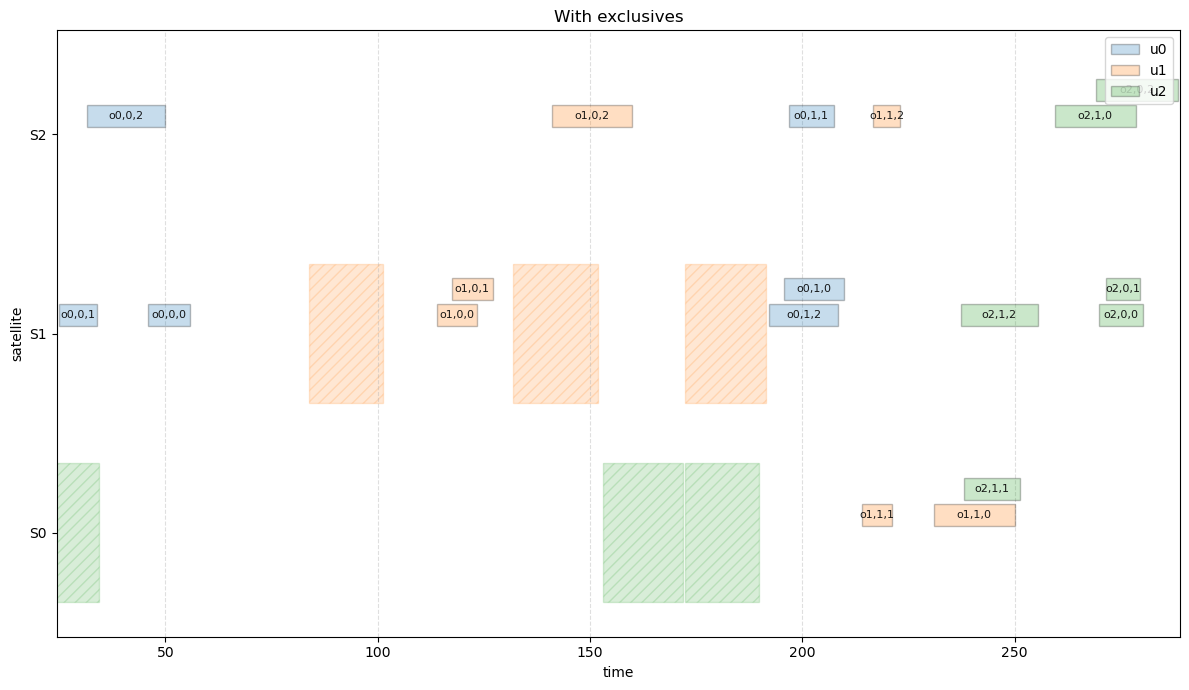

In [27]:
plot_eoscsp_windows(eoscsp_2, title="With exclusives", show_exclusives=True)

### 2.2 - Méthode de planification

Dans un second temps, nous avons conçu une méthode de planification permettant à un utilisateur de planifier l’exécution d’un ensemble de tâches sur un satellite en tenant compte des contraintes temporelles sur ces tâches.

Dans le but de trouver une solution optimale du plan calculé, mais en limitant tout de même le temps de calcul nécessaire à cette génération, nous comptons implémenter une heuristique gloutonne permettant de trouver un plan capable d'optimiser la récompense perçue, pour un utilisateur et un stallite spécifiquement. 

Pour cela, nous devons créer certaines fonctions représentant les contraintes que doit respecter notre algorithme.

#### Contraintes pour la solution

- **feasible_window** : vérifie que l’observation peut être exécutée entièrement dans sa fenêtre temporelle propre, c’est-à-dire que sa fin (start + duration) ne dépasse pas o.t_end.
- **feasible_transition** : garantit le respect du temps de transition entre deux observations consécutives sur un même satellite. Ainsi, l’observation courante ne peut commencer qu’après la fin de la précédente augmentée du coût de transition tau.
- **feasible_no_overlap** : assure l’absence de chevauchement temporel réel entre observations déjà planifiées sur le même satellite, donc les observations sur des satellites différents ne sont pas en conflit.
- **feasible_capacity** : vérifie la contrainte de capacité du satellite, en limitant le nombre total d’observations planifiées à kappa.
- **feasible_one_obs_per_request** : garantit qu’au plus une observation est sélectionnée par requête, en rejetant toute observation dont la requête a déjà été attribuée.
- **feasible_exclusive** : vérifie le respect des zones exclusives utilisateurs. Donc, si une observation sélectionnée chevauche une fenêtre exclusive sur un satellite donné, alors elle n’est autorisée que pour l’utilisateur propriétaire de cette exclusivité.

In [28]:
def feasible_window(o, start): # (10)
    return start + o.duration <= o.t_end

In [29]:
def feasible_transition(prev, prev_end, curr, start, tau, eps=1e-9):  # (5)(6)
    return start >= prev_end + tau(prev, curr) - eps

In [30]:
def feasible_no_overlap(o, start, end, plan, eps=1e-9): # non chevauchement réel
    o_sid = getattr(o.s, "s_id", o.s)

    for (obs2, s2, e2) in plan:
        s2_sid = getattr(obs2.s, "s_id", obs2.s)

        # satellites différents => aucun conflit
        if s2_sid != o_sid:
            continue

        # même satellite => pas de chevauchement autorisé
        if overlap(start, end, s2, e2, eps=eps):
            return False

    return True

In [31]:
def feasible_capacity(plan, sat): # (7)
    return len(plan) < sat.kappa

In [32]:
def feasible_one_obs_per_request(o, selected_requests): # (8)
    return o.r not in selected_requests

In [33]:
def feasible_exclusive(o, start, end, users): # exclusives (exécution réelle)
    for u in users:
        for (s,xs,xe) in u.e:
            if s == o.s and overlap(start, end, xs, xe):
                return o.u == u
    return True

### Helpers
Les fonctions suivantes nous ont aussi été utiles pour l'implémentation de la fonction greedy que nous verrons par la suite :
- **is_exclusive** teste si un utilisateur est exclusif, c’est-à-dire s’il possède au moins une fenêtre d’exclusivité (u.e non vide).
- **overlaps_strict** vérifie s’il existe un chevauchement strict entre deux intervalles temporels ouverts ; les intervalles qui ne font que se toucher aux bornes ne sont pas considérés comme chevauchants.
- **iter_exclusive_windows_on_sat** itère sur toutes les fenêtres d’exclusivité d’un utilisateur associées à un satellite donné, en normalisant les formats possibles des fenêtres.
- **domains_for** génère les domaines temporels valides pour une observation et un utilisateur :
    - si l’utilisateur n’est pas exclusif, toute la fenêtre de l’observation est autorisée,
    - sinon, seules les intersections entre la fenêtre de l’observation et les fenêtres exclusives de l’utilisateur sur le satellite sont retournées.
- **overlaps_any_exclusive_interval** indique si un intervalle temporel donné sur un satellite chevauche au moins une fenêtre exclusive sur l’ensemble considéré.
- **plan_reward** calcule la récompense totale d’un plan d’observations en sommant les récompenses individuelles des observations planifiées.

In [ ]:
def is_exclusive(u):
    return bool(getattr(u, "e", None))

def overlaps_strict(a1, a2, b1, b2):
    return max(a1, b1) < min(a2, b2)

def iter_exclusive_windows_on_sat(u, s):
    for item in getattr(u, "e", []) or []:
        if isinstance(item, tuple) and len(item) == 3:
            sat, xs, xe = item
        elif isinstance(item, tuple) and len(item) == 2 and isinstance(item[1], tuple):
            sat, (xs, xe) = item
        else:
            continue
        if sat == s:
            yield float(xs), float(xe)

def domains_for(o, u):
    if not is_exclusive(u):
        yield (o.s, float(o.t_start), float(o.t_end))
        return

    ok = False
    for xs, xe in iter_exclusive_windows_on_sat(u, o.s):
        a = max(float(o.t_start), xs)
        b = min(float(o.t_end), xe)
        if a <= b:
            ok = True
            yield (o.s, a, b)
    if not ok:
        return

def overlaps_any_exclusive_interval(sat, start, end, U_ex):
    for uex in U_ex:
        for xs, xe in iter_exclusive_windows_on_sat(uex, sat):
            if overlaps_strict(float(start), float(end), float(xs), float(xe)):
                return True
    return False

def plan_reward(plan):
    return sum(float(getattr(o, "reward", 0.0)) for o, _, _ in plan)

#### Génération d'une solution
- **gaps** a pour but de retourner les zones disponibles pour savoir quelles observations sont possibles.
- **generate_solution** évalue, de façon gloutonne, le meilleur plan d'observations possible pour un utilisateur et un satellite prédéfini. Pour cela, elle trie les tâches selon le score qu'elles rapporteraient si elles étaient prises, puis vérifie plusieurs contraintes telles que la capacité du satellite, qu'il y ait qu'une seule observation sélectionnée par requête, ou aussi qu'il n'y ait pas de chevauchement avec une autre observation sélectionnée. Elle retourne ensuite la solution idéale en itérant jusqu'à qu'il n'y ait plus d'observations possibles, ainsi que la récompense totale et le plan final.

In [35]:
def gaps(plan, t_min, t_max):
    if not plan:
        return [(t_min, t_max, None, None)]

    plan = sorted(plan, key=lambda x: x[1])
    res = []

    # before first
    first = plan[0]
    if t_min < first[1]:
        res.append((t_min, first[1], None, first))

    # between
    for i in range(len(plan) - 1):
        prev_item = plan[i]
        next_item = plan[i + 1]
        if prev_item[2] < next_item[1]:
            res.append((prev_item[2], next_item[1], prev_item, next_item))

    # after last
    last = plan[-1]
    if last[2] < t_max:
        res.append((last[2], t_max, last, None))
    return res

In [36]:
def generate_solution(tasks, users=None, lam=0.1, eps=1e-6, tau=tau, sol_id=0, debug=False):
    if not tasks:
        return Solution(sol_id, {}), 0.0, []

    # mono-satellite
    sids = {getattr(t.s, "s_id", id(t.s)) for t in tasks}
    if len(sids) != 1:
        raise ValueError("generate_solution() attend des tasks d'un seul satellite")

    sat = tasks[0].s
    t_min, t_max = sat.t_start, sat.t_end

    def score(o):
        slack = o.t_end - o.t_start
        return (o.reward / o.duration) + lam * (1.0 / max(slack, eps))

    tasks_sorted = sorted(tasks, key=lambda o: (-score(o), o.t_end))

    plan = []
    tot_reward = 0.0
    selected_requests = set()

    for o in tasks_sorted:
        # capacity kappa
        if not feasible_capacity(plan, sat):
            break

        # one obs par request
        if not feasible_one_obs_per_request(o, selected_requests):
            continue

        best_start = None
        candidate_gaps = gaps(plan, t_min=t_min, t_max=t_max)

        for (g_start, g_end, prev_item, next_item) in candidate_gaps:
            start = max(o.t_start, g_start)
            end = start + o.duration

            # doit tenir dans le gap
            if end > g_end + eps:
                continue

            # transition avec le précédent (si existe)
            if prev_item is not None:
                prev_obs, prev_start, prev_end = prev_item
                if not feasible_transition(prev_obs, prev_end, o, start, tau, eps=eps):
                    continue

            # transition avec le suivant (si existe)
            if next_item is not None:
                next_obs, next_start, next_end = next_item
                if end + tau(o, next_obs) > next_start + eps:
                    continue

            # non-chevauchement
            if not feasible_no_overlap(o, start, end, plan, eps=eps):
                continue

            best_start = start
            break

        if best_start is not None:
            plan.append((o, best_start, best_start + o.duration))
            plan.sort(key=lambda x: x[1])
            tot_reward += o.reward
            selected_requests.add(o.r)

    M = {obs: start for (obs, start, end) in plan}
    return Solution(sol_id=sol_id, M=M), tot_reward, plan


#### Greedy solver pour l'approche enchère
- **first_slot** tente d’insérer une observation dans l’emploi du temps d’un satellite au plus tôt, en tenant compte des fenêtres autorisées et des temps de transition tau. Si l’insertion est valide, elle met à jour R et renvoie l’heure de début.
- **greedy_solver** applique une stratégie gloutonne : on parcourt les observations triées et on insère dès que possible dans la timeline (first_slot). Une fois une requête servie, toutes les alternatives de cette requête sont supprimées.

In [ ]:
def first_slot(o, u, R, tau):

    s = o.s
    if len(R[s]) >= s.kappa:
        return None

    for sat, t_start, t_end in domains_for(o, u):

        if len(R[sat]) == 0:
            if float(t_start) + float(o.duration) <= float(t_end):
                R[sat].append((o, float(t_start)))
                return float(t_start)
            continue

        i = 0
        while i <= len(R[sat]):
            t_prime = float(t_start)

            if i > 0:
                o_prev, t_prev = R[sat][i - 1]
                t_prime = max(
                    t_prime,
                    float(t_prev) + float(o_prev.duration) + float(tau(o_prev, o))
                )

            if t_prime + float(o.duration) <= float(t_end):
                if i == len(R[sat]):
                    R[sat].insert(i, (o, t_prime))
                    return t_prime
                else:
                    o_next, t_next = R[sat][i]
                    t_upper = float(t_next) - float(o.duration) - float(tau(o, o_next))
                    if t_prime <= t_upper:
                        R[sat].insert(i, (o, t_prime))
                        return t_prime

            i += 1

    return None

def greedy_solver(P, tau, u=None, restrict_to_exclusives=False, obs_pool=None):

    M_dict = {}
    if obs_pool is None:
        O_sorted = list(P.O)
    else:
        O_sorted = list(obs_pool)

    if u is not None:
        O_sorted = [o for o in O_sorted if o.u == u]

    O_sorted.sort(key=lambda o: (getattr(o, "p", 0), float(o.t_start)))
    R = {s: [] for s in P.S}

    if restrict_to_exclusives:
        if u is None:
            raise ValueError("restrict_to_exclusives=True nécessite de fournir u.")
        u_ctx = u
    else:
        u_ctx = type("NonExclusiveUser", (), {"e": []})()


    i = 0
    while i < len(O_sorted):
        o = O_sorted[i]
        t = first_slot(o, u_ctx, R, tau)
        if t is not None:
            M_dict[o] = float(t)

            r = getattr(o, "r", None)
            if r is not None:
                O_sorted = [oo for oo in O_sorted if getattr(oo, "r", None) != r]
                continue

        i += 1

    plan = [(o, t, t + float(o.duration)) for o, t in M_dict.items()]
    plan.sort(key=lambda x: x[1])
    reward = plan_reward(plan)
    return M_dict, reward, plan

In [38]:
def observations_one_user_one_satellite(observations, u_id, s_id):
    tasks = []
    for o in observations :
        if o.u.u_id == u_id and o.s.s_id == s_id:
            tasks.append(o)
    return tasks

#### Test sur une instance de generate_solution

In [39]:
horizon = 300.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 4, horizon, 5.0, 15.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

# user 0
obs_u0 = [o for o in observations if o.u.u_id == 0]
by_sat = {}
for o in obs_u0:
    by_sat.setdefault(o.s.s_id, []).append(o)

best_sid = max(by_sat, key=lambda sid: len(by_sat[sid]))
print(best_sid)
observations_u0_best = by_sat[best_sid]
solution, reward, plan = generate_solution(observations_u0_best, tau=tau)

0


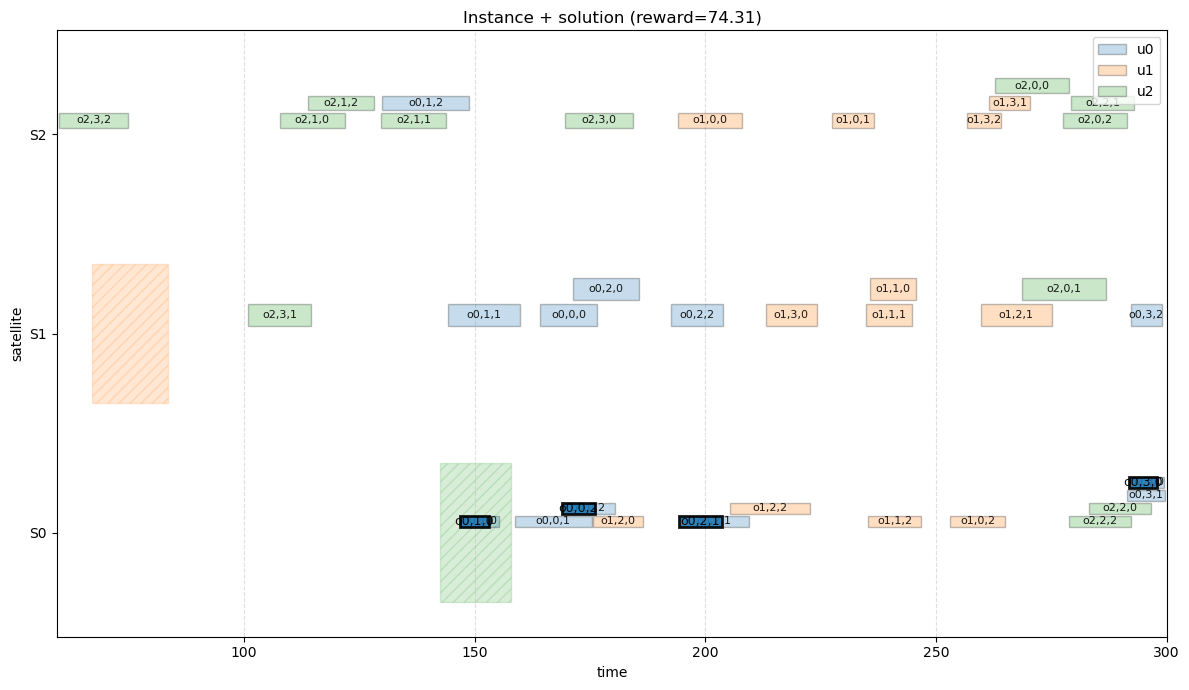

In [40]:
plot_eoscsp_windows(
    eoscsp_2,
    plan=plan,
    title=f"Instance + solution (reward={reward:.2f})",
    show_exclusives=True,
    show_labels=True,  
    show_plan_labels=True
)

In [41]:
# instance
P = generate_EOSCSP(2, satellites, users, requests, observations)
print(format_eoscsp(P, max_items=50))

EOSCSP instance #2
|S|=3 |U|=3 |R|=12 |O|=36

Satellites:
  S0: horizon=[0.00,300.00] kappa=172
  S1: horizon=[0.00,300.00] kappa=176
  S2: horizon=[0.00,300.00] kappa=132

Users:
  u0: priority=9 exclusives=0
  u1: priority=8 exclusives=3
    - (S1, [4.78,21.77])
    - (S1, [33.02,50.90])
    - (S1, [67.12,83.45])
  u2: priority=5 exclusives=3
    - (S0, [3.55,21.18])
    - (S0, [30.70,49.92])
    - (S0, [142.48,157.91])

Requests:
  r0: user=u1 duration=5.9828072895293305 reward=7.837423124185385
  r1: user=u1 duration=10.067993632550186 reward=5.158985376457965
  r2: user=u1 duration=9.52804145937595 reward=48.692073801954095
  r3: user=u1 duration=6.060486804087635 reward=29.63387117464907
  r4: user=u0 duration=7.237636505918984 reward=28.309403087007762
  r5: user=u0 duration=6.2239869640982235 reward=31.996126248186012
  r6: user=u0 duration=9.133489607939417 reward=7.302404597723813
  r7: user=u0 duration=6.1011707792360825 reward=6.7004614767686395
  r8: user=u2 duration=6.727

In [42]:
print(format_solution(solution, title="Greedy planning solution"))

Greedy planning solution
Planned observations: 4

Total reward (sum of planned observations): 74.31

Satellite S0:
  o3 (r5 u0): start=146.81 end=153.04 dur=6.22 reward=32.00
  o26 (r4 u0): start=168.87 end=176.10 dur=7.24 reward=28.31
  o10 (r6 u0): start=194.38 end=203.52 dur=9.13 reward=7.30
  o12 (r7 u0): start=291.90 end=298.01 dur=6.10 reward=6.70


## 3 - Partie 1 : Optimisation de contraintes distribuées

Dans cette partie, nous allons générer 

#### DCOP Model

Dans un premier temps, nous récupérons l'ensemble des agents exclusifs capables de répondre à la requête r, leurs fenêtres exclusives, et les observations compatibles. (13)

In [181]:
def compute_A_and_Oru(r, theta_r_obs, Uex, eps=1e-9):
    A = []
    Oru = {}
    E_u = {}

    for u in Uex:
        uid = u.u_id
        exclus = list(getattr(u, "e", []) or [])
        E_u[uid] = exclus

        obs_ok = []
        for o in theta_r_obs:
            for (s, xs, xe) in exclus:
                if getattr(s, "s_id", None) != getattr(o.s, "s_id", None):
                    continue
                if overlap(xs, xe, o.t_start, o.t_end, eps=eps):
                    obs_ok.append(o)
                    break

        if obs_ok:
            A.append(u)
            Oru[uid] = obs_ok

    return A, Oru, E_u


Cette fonction nous permet d'évaluer la capacité des satellites, afin de respecter la contrainte de capacité des satellites. (16)

In [182]:
def satellite_remaining_capacity(EOSCSP, plans_u):
    used = {}
    for sat in EOSCSP.S:
        sid = sat.s_id
        used[sid] = 0

    for uid, plan in plans_u.items():
        for (o, st, en) in plan:
            sid = o.s.s_id
            used[sid] = used.get(sid, 0) + 1

    kappa_star = {}
    for sat in EOSCSP.S:
        sid = sat.s_id
        kappa_star[sid] = max(0, sat.kappa - used.get(sid, 0))

    return kappa_star


Celle-ci nous rend la fonction objectif afin de maximiser la solution. **pi_cost** permet d’évaluer l’impact négatif potentiel d’une observation sur un plan existant, en termes de perte de récompense.

In [ ]:
def pi_cost(o, plan_u, users, lam=0.1, tau=None):
    # On ne garde que les tâches du même satellite que o
    sid_o = getattr(o.s, "s_id", id(o.s))
    tasks_same_sat = [obs for (obs, st, en) in plan_u
                      if getattr(obs.s, "s_id", id(obs.s)) == sid_o]

    # reward avant ajout de o, sur ce satellite uniquement
    plan_u_same_sat = [(obs, st, en) for (obs, st, en) in plan_u
                       if getattr(obs.s, "s_id", id(obs.s)) == sid_o]
    rew1 = plan_reward(plan_u_same_sat)

    # reward après ajout de o, en réoptimisant seulement ce satellite
    sol2, rew2, plan2 = generate_solution(tasks_same_sat + [o], users=users, lam=lam, tau=tau)

    # coût positif si on perd du reward ; 0 si on gagne
    return max(0.0, rew1 - rew2)

Ce bout de code a pour but de vérifier es contraintes suivantes :
- l’exclusivité concerne le même satellite que l’observation ;
- l’observation et l’exclusivité possèdent une intersection temporelle non vide ;
- la durée de l’observation est compatible avec cette intersection.

In [184]:
# def intersect(a_start, a_end, b_start, b_end):
#     return max(a_start, b_start), min(a_end, b_end)

# def feasible_start_in_exclusive(o, e, eps=1e-9):
#     s, xs, xe = e
#     if s.s_id != o.s.s_id:
#         return None
#     a, b = intersect(xs, xe, o.t_start, o.t_end)
#     start = a
#     if start + o.duration <= b + eps:
#         return start
#     return None

### Résumé des fonctions DCOP / résolution EOSCSP

Nous vous présentons dans cette partie, nos méthodes d'implémentation pour construire un DCOP par requête, pour ensuite le résoudre via un algorithme (dsa, dpop, mgm, maxsum) de la librairie pydcop, et enfin appliquer le résultat dans le but de produire le plan global. 

- **request_to_dcop** construit, pour chaque requête, un DCOP local (exporté en YAML) incluant uniquement les affectations faisables dans les fenêtres exclusives, avec des coûts souples représentant l’impact sur le plan courant et des contraintes dures (une observation par requête, capacité satellite, unicité agent–observation).
- **solve_dcop** appelle le solveur pyDCOP en ligne de commande avec l’algorithme choisi (DSA, MGM, MaxSum, DPOP) et récupère la sortie de résolution.
- **parse_assignment** extrait l’affectation binaire des variables DCOP depuis la sortie texte du solveur.
- **dcop_solver** orchestre l’ensemble du processus :
    - planification initiale des utilisateurs exclusifs par heuristique gloutonne ;
    - résolution DCOP par requête pour arbitrer les conflits ;
    - planification finale des utilisateurs non exclusifs sur les observations restantes ;
    - production d’un plan global par concaténation des plans individuels.

In [ ]:
BIG = 10**6

def request_to_dcop(
    EOSCSP,
    r,
    theta_r_obs,
    Uex,
    plans_u,
    users_all,
    lam=0.1,
    tau=None,
    out_yaml_path="req.yaml",
    eps=1e-9
):
    A, Oru, E_u = compute_A_and_Oru(r, theta_r_obs, Uex, eps=eps)
    kappa_star = satellite_remaining_capacity(EOSCSP, plans_u)

    domains = {"bin": {"values": [0, 1]}}
    variables = {}
    constraints = {}
    agents = [f"u{u.u_id}" for u in A]

    # index pour contrainte "at most one obs for request"
    all_vars = []

    # (X) Construire variables x_{e,o} qui sont réellement faisables et stocker les infos nécessaires (sat, start, end, obs)
    var_info = {}  # var -> (uid, obs, satid)
    for u in A:
        uid = u.u_id
        for o in Oru[uid]:

            # st = feasible_start_in_exclusive(o, e, eps=eps)
            # if st is None:
            #     continue
            st = o.t_start
            var = f"x_u{uid}_s{o.s.s_id}_o{o.o_id}"
            variables[var] = {"domain": "bin"}
            all_vars.append(var)
            var_info[var] = (uid, o, o.s.s_id, st, st + o.duration)

            # soft cost: c(x)=pi(o, M_u) if x=1 else 0
            cost = pi_cost(o, plans_u.get(uid, []), users_all, lam=lam, tau=tau)
            constraints[f"cost_{var}"] = {
                "type": "intention",
                "function": f"{cost} if {var} == 1 else 0"
            }

    # au plus une variable x_{e,o} == 1 (pour cette requête)
    if all_vars:
        cnt = " + ".join(all_vars)
        constraints["one_obs_for_request"] = {
            "type": "intention",
            "function": f"{BIG} if ({cnt}) > 1 else 0"
        }

    # capacité satellite restante
    # Somme des x d'un satellite s <= kappa_star[s]
    for sat in EOSCSP.S:
        sid = sat.s_id
        cap = kappa_star.get(sid, sat.kappa)
        vars_on_sat = [v for v,info in var_info.items() if info[2] == sid]
        if vars_on_sat:
            cnt = " + ".join(vars_on_sat)
            constraints[f"cap_s{sid}"] = {
                "type": "intention",
                "function": f"{BIG} if ({cnt}) > {cap} else 0"
            }

    # Somme des x_{*,o} <= 1 pour chaque o
    obs_to_vars = {}
    for v, (uid, o, sid, st, en) in var_info.items():
        obs_to_vars.setdefault(o.o_id, []).append(v)

    for oid, vars_for_o in obs_to_vars.items():
        if len(vars_for_o) > 1:
            cnt = " + ".join(vars_for_o)
            constraints[f"one_agent_for_o{oid}"] = {
                "type": "intention",
                "function": f"{BIG} if ({cnt}) > 1 else 0"
            }

    dcop = {
        "name": f"s_dcop_req_{r.r_id}",
        "objective": "min",
        "domains": domains,
        "variables": variables,
        "constraints": constraints,
        "agents": agents
    }

    out_yaml_path = str(Path(out_yaml_path))
    with open(out_yaml_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(dcop, f, sort_keys=False, allow_unicode=True)

    return out_yaml_path, var_info


In [186]:
def solve_dcop(
    yaml_path,
    algo,
    timeout_s = None,
    algo_params = None,
    extra_args = None,
    cwd = None,
):

    yaml_path = str(Path(yaml_path))

    cmd = ["pydcop", "solve", "--algo", algo]

    if timeout_s is not None:
        cmd += ["--timeout", str(timeout_s)]

    if algo_params:
        # format CLI pyDCOP: --algo_params key:value,key2:value2
        ap = ",".join(f"{k}:{v}" for k, v in algo_params.items())
        cmd += ["--algo_params", ap]

    if extra_args:
        cmd += extra_args

    cmd.append(yaml_path)

    proc = subprocess.run(
        cmd,
        capture_output=True,
        text=True,
        cwd=cwd
    )
    return proc.returncode, proc.stdout, proc.stderr


In [188]:
def parse_assignment(stdout):
    assignment = {}

    # regex: variable = value  ou  variable: value
    pattern = re.compile(
        r"(x_[A-Za-z0-9_\.]+)\s*(?:=|:|->)\s*([01])"
    )

    for line in stdout.splitlines():
        line = line.strip()
        m = pattern.search(line)
        if m:
            var = m.group(1)
            val = int(m.group(2))
            assignment[var] = val

    return assignment

In [ ]:
def dcop_solver(P, tau, algo="dsa"):
    plans_u = {}
    observations_to_sup = set()
    served_rids = set()  # GLOBAL: une seule observation par requête (via r_id)

    # Étape 1 : plans initiaux des users exclusifs (par satellite unique, sans doublons)
    for u in P.U:
        if not getattr(u, "e", None):
            continue

        uid = u.u_id
        plans_u[uid] = []

        sat_ids = {s.s_id for (s, xs, xe) in (u.e or [])}
        for sid in sat_ids:
            obs_u_s = observations_one_user_one_satellite(P.O, uid, sid)
            if not obs_u_s:
                continue

            obs_u_s = [o for o in obs_u_s if o.r.r_id not in served_rids]
            if not obs_u_s:
                continue

            _, _, plan = generate_solution(obs_u_s, users=P.U, tau=tau)

            for (obs, st, en) in plan:
                rid = obs.r.r_id
                if rid in served_rids:
                    continue
                plans_u[uid].append((obs, st, en))
                served_rids.add(rid)

        plans_u[uid].sort(key=lambda x: x[1])

    # Étape 2 : boucle DCOP sur les requêtes
    for r in sorted(P.R, key=lambda r: r.t_end):

        if r.r_id in served_rids:
            continue

        theta_r = [o for o in P.O if o.r == r]
        if not theta_r:
            continue

        yaml_path, var_info = request_to_dcop(
            EOSCSP=P,
            r=r,
            theta_r_obs=theta_r,
            Uex=[u for u in P.U if getattr(u, "e", None)],
            plans_u=plans_u,
            users_all=P.U,
            tau=tau,
        )

        res, out, err = solve_dcop(yaml_path, algo=algo)
        if res != 0:
            continue

        assignment = parse_assignment(out)

        chosen = [v for v, val in assignment.items() if str(val) in ("1", "1.0", "True")]
        for v in chosen:
            if v not in var_info:
                continue
            uid, obs, sid, st, en = var_info[v]
            rid = obs.r.r_id
            if rid in served_rids:
                continue

            plans_u.setdefault(uid, [])
            if any(obs2.o_id == obs.o_id for (obs2, _, _) in plans_u[uid]):
                continue

            plans_u[uid].append((obs, st, en))
            plans_u[uid].sort(key=lambda x: x[1])
            served_rids.add(rid)

    #  Marquage des observations déjà prises
    for plan in plans_u.values():
        for (o, start, end) in plan:
            observations_to_sup.add(o)
            served_rids.add(o.r.r_id)

    # Étape 3 : planification des observations restantes
    for u in P.U:
        uid = u.u_id
        plans_u.setdefault(uid, [])

        obs_u = [
            o for o in P.O
            if o.u.u_id == uid
            and o not in observations_to_sup
            and o.r.r_id not in served_rids
        ]
        if not obs_u:
            continue

        # regrouper les observations par satellite
        obs_by_sat = {}
        for o in obs_u:
            obs_by_sat.setdefault(o.s.s_id, []).append(o)

        # planifier satellite par satellite
        for sid, obs_u_s in obs_by_sat.items():

            obs_u_s = [o for o in obs_u_s if o.r.r_id not in served_rids]
            if not obs_u_s:
                continue

            _, _, plan = generate_solution(obs_u_s, users=P.U, tau=tau)


            for (obs, st, en) in plan:
                rid = obs.r.r_id
                if rid in served_rids:
                    continue

                if any(obs2.o_id == obs.o_id for (obs2, _, _) in plans_u[uid]):
                    continue

                plans_u[uid].append((obs, st, en))
                served_rids.add(rid)
                observations_to_sup.add(obs)

        plans_u[uid].sort(key=lambda x: x[1])

    # Étape 4 : concaténation des plans individuels
    global_plan = []
    for plan in plans_u.values():
        global_plan.extend(plan)

    return plans_u, global_plan


#### Tests

In [190]:
horizon = 300.0
satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 5.0, 15.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)
P = generate_EOSCSP(1, satellites, users, requests, observations)

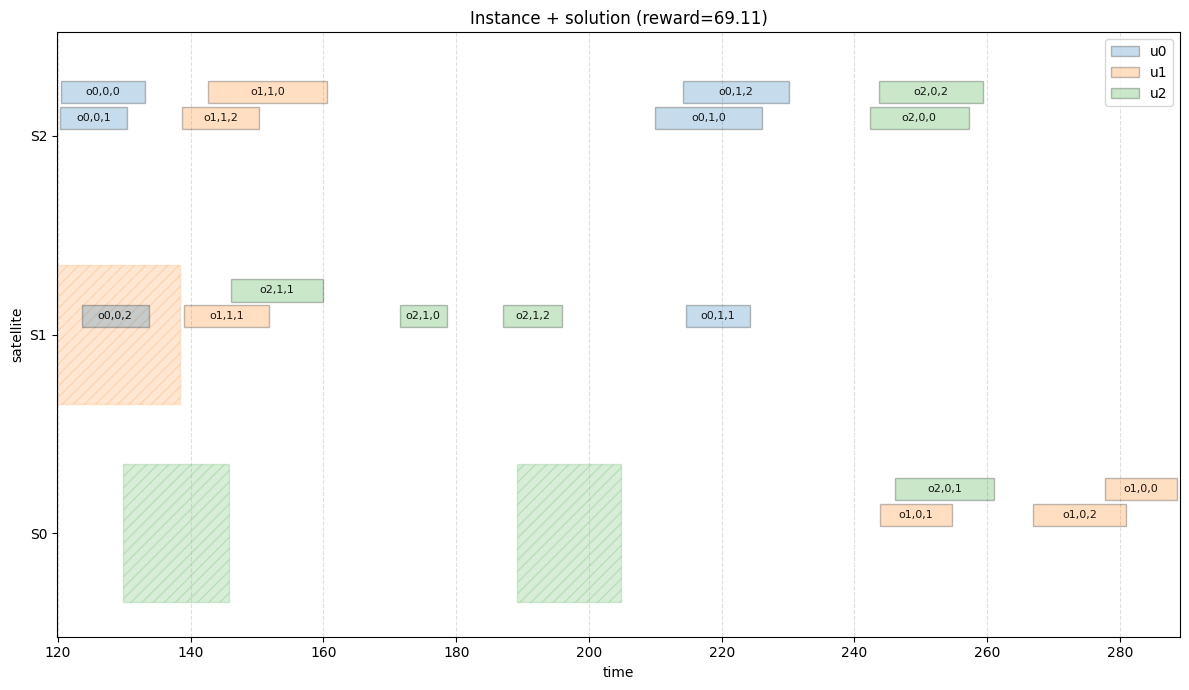

In [191]:
plot_eoscsp_windows(
P,
plan=None,
title=f"Instance + solution (reward={reward:.2f})",
show_exclusives=True,
show_labels=True,  
show_plan_labels=True
)

In [ ]:
plans_u, global_plan = dcop_solver(P, tau=tau)

print("\n=== Final plans after s_dcop ===")
for o, st, en in global_plan:
    print(f"User u{o.u.u_id}:")
    print(f"  obs o{o.o_id} on S{o.s.s_id} [{st:.1f},{en:.1f}] r{o.r.r_id}")

plot_eoscsp_windows(
P,
plan=global_plan,
title=f"Instance + solution (reward={reward:.2f})",
show_exclusives=True,
show_labels=True,  
show_plan_labels=True
)
print(format_eoscsp(P))

In [125]:

# for algo in ["dsa", "mgm", "maxsum", "dpop"]:
#     print(f"\n=== Running s_dcop with {algo} ===")
#     plans_u, global_plan = s_dcop_EOSCSP_solver(eoscsp_2, tau=tau, algo=algo)
#     total = sum(o.reward for plan in plans_u.values() for (o,_,_) in plan)
#     print(f"Total reward with {algo}: {total:.2f}")
#     plot_eoscsp_windows(
#     P,
#     plan=global_plan,
#     title=f"Instance + solution (reward={reward:.2f})",
#     show_exclusives=True,
#     show_labels=True,  
#     show_plan_labels=True
#     )

In [126]:
#print(format_eoscsp(P))

## 4 - Partie 2 : Approches par enchères

### Utils:
- **solve_rest** une fois le plan partiel M_u0 fixé par l’enchère, on remplit gloutonnement avec des observations restantes.
- **bid** renvoie la meilleure observation de la requête r que u peut ajouter à son plan courant, en maximisant le reward sous contraintes de faisabilité.
- **compute_best_and_second_bids** calcule le meilleur et deuxieme meilleur bid

In [43]:
def solve_rest(P, M_fixed, U_ex, u0, tau):
    """solve(P[u0 | M_fixed]) : complète hors exclusives."""
    R = {s: [] for s in P.S}
    served = set()
    plan = list(M_fixed)

    for o, t, _ in M_fixed:
        R[o.s].append((o, float(t)))
        if getattr(o, "r", None) is not None:
            served.add(o.r)
    for s in R:
        R[s].sort(key=lambda x: x[1])

    candidates = [o for o in P.O if getattr(o, "r", None) not in served]
    candidates.sort(key=lambda o: (getattr(o, "p", 0), float(o.t_start)))

    for o in candidates:
        r = getattr(o, "r", None)
        if r is not None and r in served:
            continue

        t = first_slot(o, u0, R, tau)
        if t is None:
            continue
        end = t + float(o.duration)

        if overlaps_any_exclusive_interval(o.s, t, end, U_ex):

            R[o.s] = [(oo, tt) for (oo, tt) in R[o.s] if not (oo == o and abs(tt - t) < 1e-9)]
            continue

        plan.append((o, t, end))
        if r is not None:
            served.add(r)

    plan.sort(key=lambda x: x[1])
    return plan


def bid(P, r, u, M_u_plan, tau):
    """
    - reconstruit timeline depuis M_u
    - choisit l'observation de r de reward max insérable
    Retour: (best_gain, sigma=(o,t)) ou (-inf,None)
    """
    R = {s: [] for s in P.S}
    served = set()
    for obs, st, _ in M_u_plan:
        R[obs.s].append((obs, float(st)))
        if getattr(obs, "r", None) is not None:
            served.add(obs.r)
    for s in R:
        R[s].sort(key=lambda x: x[1])

    if r in served:
        return float("-inf"), None

    cand = [o for o in P.O if getattr(o, "r", None) == r]
    best_b = float("-inf")
    best_sigma = None

    for o in cand:

        ok = False
        for _ in domains_for(o, u):
            ok = True
            break
        if not ok:
            continue

        Rcopy = {s: list(R[s]) for s in R}
        t = first_slot(o, u, Rcopy, tau)
        if t is None:
            continue

        gain = float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0)
        if gain > best_b:
            best_b = gain
            best_sigma = (o, t)

    return best_b, best_sigma

def compute_best_and_second_bids(P, remaining, U_ex, M_u, tau, eps=1e-12):
    """
    Pour chaque requête r dans remaining:
      - calcule les bids des users exclusifs
      - retourne best[r] = (g1, u1, sig1)
      - retourne second_best[r] = g2 (0.0 si un seul bidder, -inf si aucun)
    """
    best = {}    # r -> (best_gain, best_u, best_sigma=(o,t))
    second_best = {}  # r -> second best gain (ou 0.0 / -inf)
    feasible = False

    for r in remaining:
        per_u = []
        for u in U_ex:
            g, sig = bid(P, r, u, M_u[u], tau)  # bid SSI standard
            if sig is None or g == float("-inf"):
                continue
            per_u.append((float(g), u, sig))

        if not per_u:
            best[r] = (float("-inf"), None, None)
            second_best[r] = float("-inf")
            continue

        feasible = True
        per_u.sort(key=lambda x: x[0], reverse=True)

        g1, u1, sig1 = per_u[0]
        g2 = per_u[1][0] if len(per_u) >= 2 else 0.0  # seul bidder => second=0

        best[r] = (g1, u1, sig1)
        second_best[r] = float(g2)

    return best, second_best, feasible

### 4.1 - Enchères parallèles (PSI)

1. Chaque utilisateur exclusif calcule un plan local et des bids pour toutes les requêtes.
2. Pour chaque requête, le meilleur bid est sélectionné et inséré dans la timeline globale.
3. Une complétion centrale finalise le plan global.

In [44]:
def psi_solver(P, tau):

    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    M_u0 = []

    # solve(P[u]) + bids "parallèles"
    M_u = {}
    bids = {}
    sigma = {}
    for u in U_ex:
        _, _, M_u[u] = greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)
        for r in P.R:
            b, sig = bid(P, r, u, M_u[u], tau)
            bids[(u, r)] = b
            sigma[(u, r)] = sig


    R0 = {s: [] for s in P.S}
    served_global = set()

    for r in P.R:
        if r in served_global:
            continue

        w = None
        best_b = float("-inf")
        best_sig = None

        for u in U_ex:
            b = bids[(u, r)]
            sig = sigma[(u, r)]
            if sig is None:
                continue
            if b > best_b:
                best_b = b
                w = u
                best_sig = sig

        if w is None or best_sig is None or best_b == float("-inf"):
            continue

        o_win, _t_win = best_sig
        t = first_slot(o_win, w, R0, tau)
        if t is None:
            continue

        M_u0.append((o_win, t, t + float(o_win.duration)))
        served_global.add(r)


    M_u0 = solve_rest(P, M_u0, U_ex, u0, tau)

    M_u0.sort(key=lambda x: x[1])
    return M_u0, plan_reward(M_u0)

### 4.2 - Enchères séquentielles (SSI)

1. Chaque utilisateur exclusif construit un plan local sur ses exclusives.
2. Les requêtes sont traitées séquentiellement : chaque user soumet un bid pour la requête courante.
3. Le meilleur bid gagne, et le plan du gagnant est mis à jour immédiatement.
4. Une complétion centrale finalise le plan global.

In [ ]:
def ssi_solver(P, tau):

    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    # Items auctionnés
    R_emit = [r for r in P.R if getattr(r, "u", None) == u0]

    # solve(P[u])
    M_u = {u: greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)[2] for u in U_ex}

    # allocations gagnées
    M_u0 = []
    served_fixed = set()

    for r in sorted(R_emit, key=lambda rr: getattr(rr, "p", 0)):
        if r in served_fixed:
            continue

        best_u = None
        best_b = float("-inf")
        best_sigma = None

        for u in U_ex:
            b, sig = bid(P, r, u, M_u[u], tau)
            if sig is None:
                continue
            if b > best_b:
                best_b = b
                best_u = u
                best_sigma = sig

        if best_u is None or best_sigma is None or best_b == float("-inf"):
            continue

        o_win, t_win = best_sigma
        alloc = (o_win, t_win, t_win + float(o_win.duration))

        M_u0.append(alloc)
        served_fixed.add(r)


        M_u[best_u].append(alloc)
        M_u[best_u].sort(key=lambda x: x[1])

    final_plan = solve_rest(P, M_u0, U_ex, u0, tau)
    final_plan.sort(key=lambda x: x[1])
    return final_plan, plan_reward(final_plan)

### 4.3 - Enchères séquentielles avec regret (SSI-Regret)

1. Chaque utilisateur exclusif construit un plan local sur ses exclusives.
2. À chaque tour, on calcule les bids et le regret pour chaque requête restante.
3. La requête de regret maximal est allouée, et le plan du gagnant est mis à jour.
4. Une complétion centrale finalise le plan global.

In [ ]:
def ssi_regret_solver(P, tau, eps=1e-12):

    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    R_emit = [r for r in P.R if getattr(r, "u", None) == u0]
    remaining = list(R_emit)

    M_u = {
        u: greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)[2]
        for u in U_ex
    }

    M_u0 = []

    while remaining:

        best_info, second_best, any_feasible = compute_best_and_second_bids(
            P, remaining, U_ex, M_u, tau, eps=eps
        )
        if not any_feasible:
            break

        # choisir r* max regret
        r_star = None
        best_regret = float("-inf")
        best_g1 = float("-inf")

        for r in remaining:
            g1, u1, sig1 = best_info[r]
            if sig1 is None or g1 == float("-inf"):
                continue

            g2 = second_best[r]
            regret = g1 - g2

            if (regret > best_regret + eps) or (abs(regret - best_regret) <= eps and g1 > best_g1 + eps):
                best_regret = regret
                best_g1 = g1
                r_star = r

        if r_star is None:
            break

        g_win, u_win, (o_win, t_win) = best_info[r_star]
        alloc = (o_win, float(t_win), float(t_win) + float(o_win.duration))

        M_u0.append(alloc)
        M_u[u_win].append(alloc)
        M_u[u_win].sort(key=lambda x: x[1])

        remaining.remove(r_star)

    final_plan = solve_rest(P, M_u0, U_ex, u0, tau)
    total_reward = plan_reward(final_plan)
    return final_plan, total_reward

## 5 - Graphiques: Runtime et Qualité

In [ ]:
# ============================
# CONFIG
# ============================
N_RUNS = 5
HORIZON = 100.0

OUT_DCOP_CSV = "results_dcop.csv"
OUT_AUC_CSV  = "results_auctions.csv"

SIZES = {
    "small":  dict(n_sats=3, n_non_ex=1, n_ex=3, req_per_user=4, obs_per_req=5),
    "medium": dict(n_sats=5, n_non_ex=2, n_ex=5, req_per_user=6, obs_per_req=6),
    "large":  dict(n_sats=7, n_non_ex=3, n_ex=7, req_per_user=8, obs_per_req=7),
}

DIFFICULTIES = {
    "easy": dict(
        dur_min=4.0, dur_max=10.0,
        slack_min=14.0, slack_max=28.0,
        ex_windows=2,
        tau_kind="mild"
    ),
    "medium": dict(
        dur_min=6.0, dur_max=16.0,
        slack_min=8.0, slack_max=18.0,
        ex_windows=3,
        tau_kind="hard"
    ),
    "hard": dict(
        dur_min=10.0, dur_max=24.0,
        slack_min=5.0, slack_max=10.0,
        ex_windows=4,
        tau_kind="hard"
    ),
}

# Si tu veux filtrer:
SIZES_TO_RUN = list(SIZES.keys())            # ex: ["small"]
DIFFS_TO_RUN = list(DIFFICULTIES.keys())     # ex: ["easy"]

# ============================
# HELPERS
# ============================
def tau_from_kind(kind):
    if kind == "hard":
        return lambda a, b: 2.0
    return lambda a, b: 1.0


def ideal_upper_bound(P):
    """
    Upper bound "théorique": somme_{r} max_{o in theta(r)} reward(o)
    Ignore contraintes -> borne sup.
    """
    best = {}
    for o in P.O:
        r = getattr(o, "r", None)
        if r is None:
            continue
        rew = float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0)
        best[r] = max(best.get(r, 0.0), rew)
    return float(sum(best.values())) if best else 0.0


def generate_instance(size_cfg, diff_cfg, horizon=HORIZON):
    # satellites
    satellites = generate_satellites(size_cfg["n_sats"], horizon, 100, 200)

    # users
    users_no_ex = generate_users(size_cfg["n_non_ex"])

    # users exclusifs (version "complète" de ton premier code)
    users_ex = generate_users_exclusifs(
        k=len(users_no_ex),
        satellites=satellites,
        nb_users=size_cfg["n_ex"],
        k_excl_per_user=diff_cfg["ex_windows"],
        e_dur_min=15.0,
        e_dur_max=20.0
    )

    users = users_no_ex.union(users_ex)

    # requests
    requests = generate_requests(
        users,
        size_cfg["req_per_user"],
        horizon,
        diff_cfg["dur_min"],
        diff_cfg["dur_max"],
        5.0,
        50.0,
    )

    # observations
    observations = generate_observations(
        satellites,
        users,
        requests,
        size_cfg["obs_per_req"],
        diff_cfg["slack_min"],
        diff_cfg["slack_max"],
    )

    P = generate_EOSCSP(0, satellites, users, requests, observations)
    return P


def run_one_algo(algo_fn, P, tau):
    t0 = time.perf_counter()
    plan, reward = algo_fn(P, tau=tau)
    t1 = time.perf_counter()
    return (t1 - t0), float(reward), plan


# ============================
# ALGO WRAPPERS (uniform interface)
# ============================
def make_pydcop_runner(algo_name):
    def _run(P, tau):
        print(f"      -> DCOP solver: {algo_name}", flush=True)
        plans_u, global_plan = dcop_solver(P, tau=tau, algo=algo_name)
        reward = sum(o.reward for (o, st, en) in global_plan)
        return global_plan, float(reward)
    return _run


DCOP_ALGOS = {
    "DCOP_dsa":    make_pydcop_runner("dsa"),
    "DCOP_mgm":    make_pydcop_runner("mgm"),
    "DCOP_maxsum": make_pydcop_runner("maxsum"),
    "DCOP_dpop":   make_pydcop_runner("dpop"),
}

AUCTION_ALGOS = {
    "PSI": psi_solver,
    "SSI": ssi_solver,
    "SSI_regret": ssi_regret_solver,
}

ALL_ALGOS = {}
ALL_ALGOS.update(DCOP_ALGOS)
ALL_ALGOS.update(AUCTION_ALGOS)

DCOP_NAMES = list(DCOP_ALGOS.keys())
AUC_NAMES  = list(AUCTION_ALGOS.keys())


# ============================
# CSV UTIL
# ============================
CSV_FIELDS = [
    "size", "difficulty", "run", "seed", "algo",
    "runtime", "reward", "ideal", "reward_ratio", "x_over_y", "n_obs"
]

def init_csv(path):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=CSV_FIELDS)
        w.writeheader()

def append_csv(path, row):
    with open(path, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=CSV_FIELDS)
        w.writerow(row)


# ============================
# RUN BENCH (SAME INSTANCES FOR ALL 7 ALGOS)
# ============================
init_csv(OUT_DCOP_CSV)
init_csv(OUT_AUC_CSV)

total_instances = len(SIZES_TO_RUN) * len(DIFFS_TO_RUN) * N_RUNS
total_calls = total_instances * len(ALL_ALGOS)

call_idx = 0
bench_t0 = time.perf_counter()

print(f"[BENCH] START", flush=True)
print(f"[BENCH] sizes={SIZES_TO_RUN} diffs={DIFFS_TO_RUN} runs={N_RUNS}", flush=True)
print(f"[BENCH] instances={total_instances} | total algo calls={total_calls}", flush=True)
print(f"[BENCH] dcop_csv={OUT_DCOP_CSV} | auctions_csv={OUT_AUC_CSV}", flush=True)

for size_name in SIZES_TO_RUN:
    size_cfg = SIZES[size_name]
    print(f"\n========== SIZE = {size_name} cfg={size_cfg} ==========", flush=True)

    for diff_name in DIFFS_TO_RUN:
        diff_cfg = DIFFICULTIES[diff_name]
        tau = tau_from_kind(diff_cfg["tau_kind"])
        print(f"\n------ DIFF = {diff_name} cfg={diff_cfg} ------", flush=True)

        for run in range(N_RUNS):
            # Seed stable pour générer UNE instance reproductible
            # (tu peux changer le 12345 pour un autre offset)
            seed = hash((size_name, diff_name, run, 12345)) % (2**32 - 1)
            random.seed(seed)
            np.random.seed(seed % (2**32 - 1))

            print(f"\n[GEN] ({run+1}/{N_RUNS}) size={size_name} diff={diff_name} seed={seed}", flush=True)
            gen_t0 = time.perf_counter()
            P = generate_instance(size_cfg, diff_cfg, horizon=HORIZON)
            gen_t1 = time.perf_counter()

            print(
                f"[OK ] generated in {(gen_t1-gen_t0):.3f}s | "
                f"|S|={len(P.S)} |U|={len(P.U)} |R|={len(P.R)} |O|={len(P.O)}",
                flush=True
            )

            ideal = ideal_upper_bound(P)
            if ideal <= 1e-12:
                ideal = 1e-12
            print(f"[INF] ideal_upper_bound={ideal:.2f}", flush=True)

            # Lancer les 7 algos SUR LA MEME instance P
            for algo_name, algo_fn in ALL_ALGOS.items():
                call_idx += 1
                elapsed_min = (time.perf_counter() - bench_t0) / 60.0

                print(
                    f"[SOL] ({call_idx}/{total_calls}) {algo_name} | "
                    f"size={size_name} diff={diff_name} run={run+1}/{N_RUNS} | "
                    f"elapsed={elapsed_min:.2f} min",
                    flush=True
                )

                try:
                    runtime, reward, plan = run_one_algo(algo_fn, P, tau)
                except Exception as e:
                    # log l'échec dans CSV avec NaN
                    print(f"[ERR] {algo_name} failed: {type(e).__name__}: {e}", flush=True)
                    row = {
                        "size": size_name, "difficulty": diff_name, "run": run,
                        "seed": seed, "algo": algo_name,
                        "runtime": float("nan"), "reward": float("nan"),
                        "ideal": ideal, "reward_ratio": float("nan"),
                        "x_over_y": float("nan"), "n_obs": 0
                    }
                    out = OUT_DCOP_CSV if algo_name in DCOP_NAMES else OUT_AUC_CSV
                    append_csv(out, row)
                    continue

                reward_ratio = reward / ideal
                x_over_y = runtime / max(reward_ratio, 1e-9)

                print(
                    f"[OK ] {algo_name} t={runtime:.3f}s reward={reward:.1f} "
                    f"ratio={reward_ratio:.3f} nobs={len(plan)}",
                    flush=True
                )

                row = {
                    "size": size_name,
                    "difficulty": diff_name,
                    "run": run,
                    "seed": seed,
                    "algo": algo_name,
                    "runtime": runtime,
                    "reward": reward,
                    "ideal": ideal,
                    "reward_ratio": reward_ratio,
                    "x_over_y": x_over_y,
                    "n_obs": len(plan),
                }

                out = OUT_DCOP_CSV if algo_name in DCOP_NAMES else OUT_AUC_CSV
                append_csv(out, row)

bench_t1 = time.perf_counter()
print(f"\n[BENCH] DONE in {(bench_t1-bench_t0)/60.0:.2f} min", flush=True)
print(f"[BENCH] wrote: {OUT_DCOP_CSV} and {OUT_AUC_CSV}", flush=True)

In [4]:
# --- charge tes CSV ---
df_auctions = pd.read_csv("results_auctions.csv")
df_dcop     = pd.read_csv("results_dcop.csv")


def compute_stats_and_raw(df: pd.DataFrame):
    # raw[size][difficulty][algo] -> list of dicts
    raw = {}
    for (size, diff, algo), g in df.groupby(["size", "difficulty", "algo"], sort=False):
        raw.setdefault(size, {}).setdefault(diff, {}).setdefault(algo, [])
        for _, row in g.iterrows():
            raw[size][diff][algo].append({
                "runtime": float(row["runtime"]),
                "reward_ratio": float(row["reward_ratio"]),
            })

    # stats[size][difficulty][algo] -> means/stds
    stats = {}
    agg = df.groupby(["size", "difficulty", "algo"]).agg(
        runtime_mean=("runtime", "mean"),
        runtime_std=("runtime", "std"),
        ratio_mean=("reward_ratio", "mean"),
        ratio_std=("reward_ratio", "std"),
    ).reset_index()

    for _, r in agg.iterrows():
        size = r["size"]; diff = r["difficulty"]; algo = r["algo"]
        stats.setdefault(size, {}).setdefault(diff, {})[algo] = {
            "runtime_mean": float(r["runtime_mean"]),
            "runtime_std": float(0.0 if pd.isna(r["runtime_std"]) else r["runtime_std"]),
            "ratio_mean": float(r["ratio_mean"]),
            "ratio_std": float(0.0 if pd.isna(r["ratio_std"]) else r["ratio_std"]),
        }
    return stats, raw


def plot_all_sizes_grid_from_df(df: pd.DataFrame, title_prefix: str = ""):
    stats, raw = compute_stats_and_raw(df)

    sizes = list(df["size"].dropna().unique())
    diffs = list(df["difficulty"].dropna().unique())
    algos = list(df["algo"].dropna().unique())

    fig, axes = plt.subplots(
        nrows=len(sizes),
        ncols=3,
        figsize=(18, 4.2 * len(sizes)),
        sharex=False
    )
    if len(sizes) == 1:
        axes = np.array([axes])

    for row, size in enumerate(sizes):
        x = np.arange(len(diffs))
        width = 0.8 / max(len(algos), 1)
        offsets = (np.arange(len(algos)) - (len(algos)-1)/2) * width

        # 1) Runtime (log)
        ax = axes[row, 0]
        for i, algo in enumerate(algos):
            means = [stats.get(size, {}).get(d, {}).get(algo, {}).get("runtime_mean", np.nan) for d in diffs]
            stds  = [stats.get(size, {}).get(d, {}).get(algo, {}).get("runtime_std", 0.0) for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3, label=algo)

        ax.set_yscale("log")
        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_title(f"{title_prefix}{size} – Runtime")
        ax.set_ylabel("runtime (s)")

        # 2) Reward ratio
        ax = axes[row, 1]
        for i, algo in enumerate(algos):
            means = [stats.get(size, {}).get(d, {}).get(algo, {}).get("ratio_mean", np.nan) for d in diffs]
            stds  = [stats.get(size, {}).get(d, {}).get(algo, {}).get("ratio_std", 0.0) for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3)

        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{title_prefix}{size} – Reward / ideal")

        # 3) Scatter runtime vs reward
        ax = axes[row, 2]
        for algo in algos:
            xs, ys = [], []
            for diff in diffs:
                for rec in raw.get(size, {}).get(diff, {}).get(algo, []):
                    xs.append(rec["runtime"])
                    ys.append(rec["reward_ratio"])
            if xs:
                ax.scatter(xs, ys, alpha=0.6, label=algo)

        ax.set_xscale("log")
        ax.set_title(f"{title_prefix}{size} – Runtime vs reward")
        ax.set_xlabel("runtime (s)")
        ax.set_ylabel("reward ratio")

        if row == 0:
            axes[row, 0].legend()
            axes[row, 2].legend()

    plt.tight_layout()
    plt.show()


# --- wrappers demandés ---
def plot_auctions():
    plot_all_sizes_grid_from_df(df_auctions, title_prefix="Auctions — ")

def plot_dcop():
    plot_all_sizes_grid_from_df(df_dcop, title_prefix="DCOP — ")


### DCOP

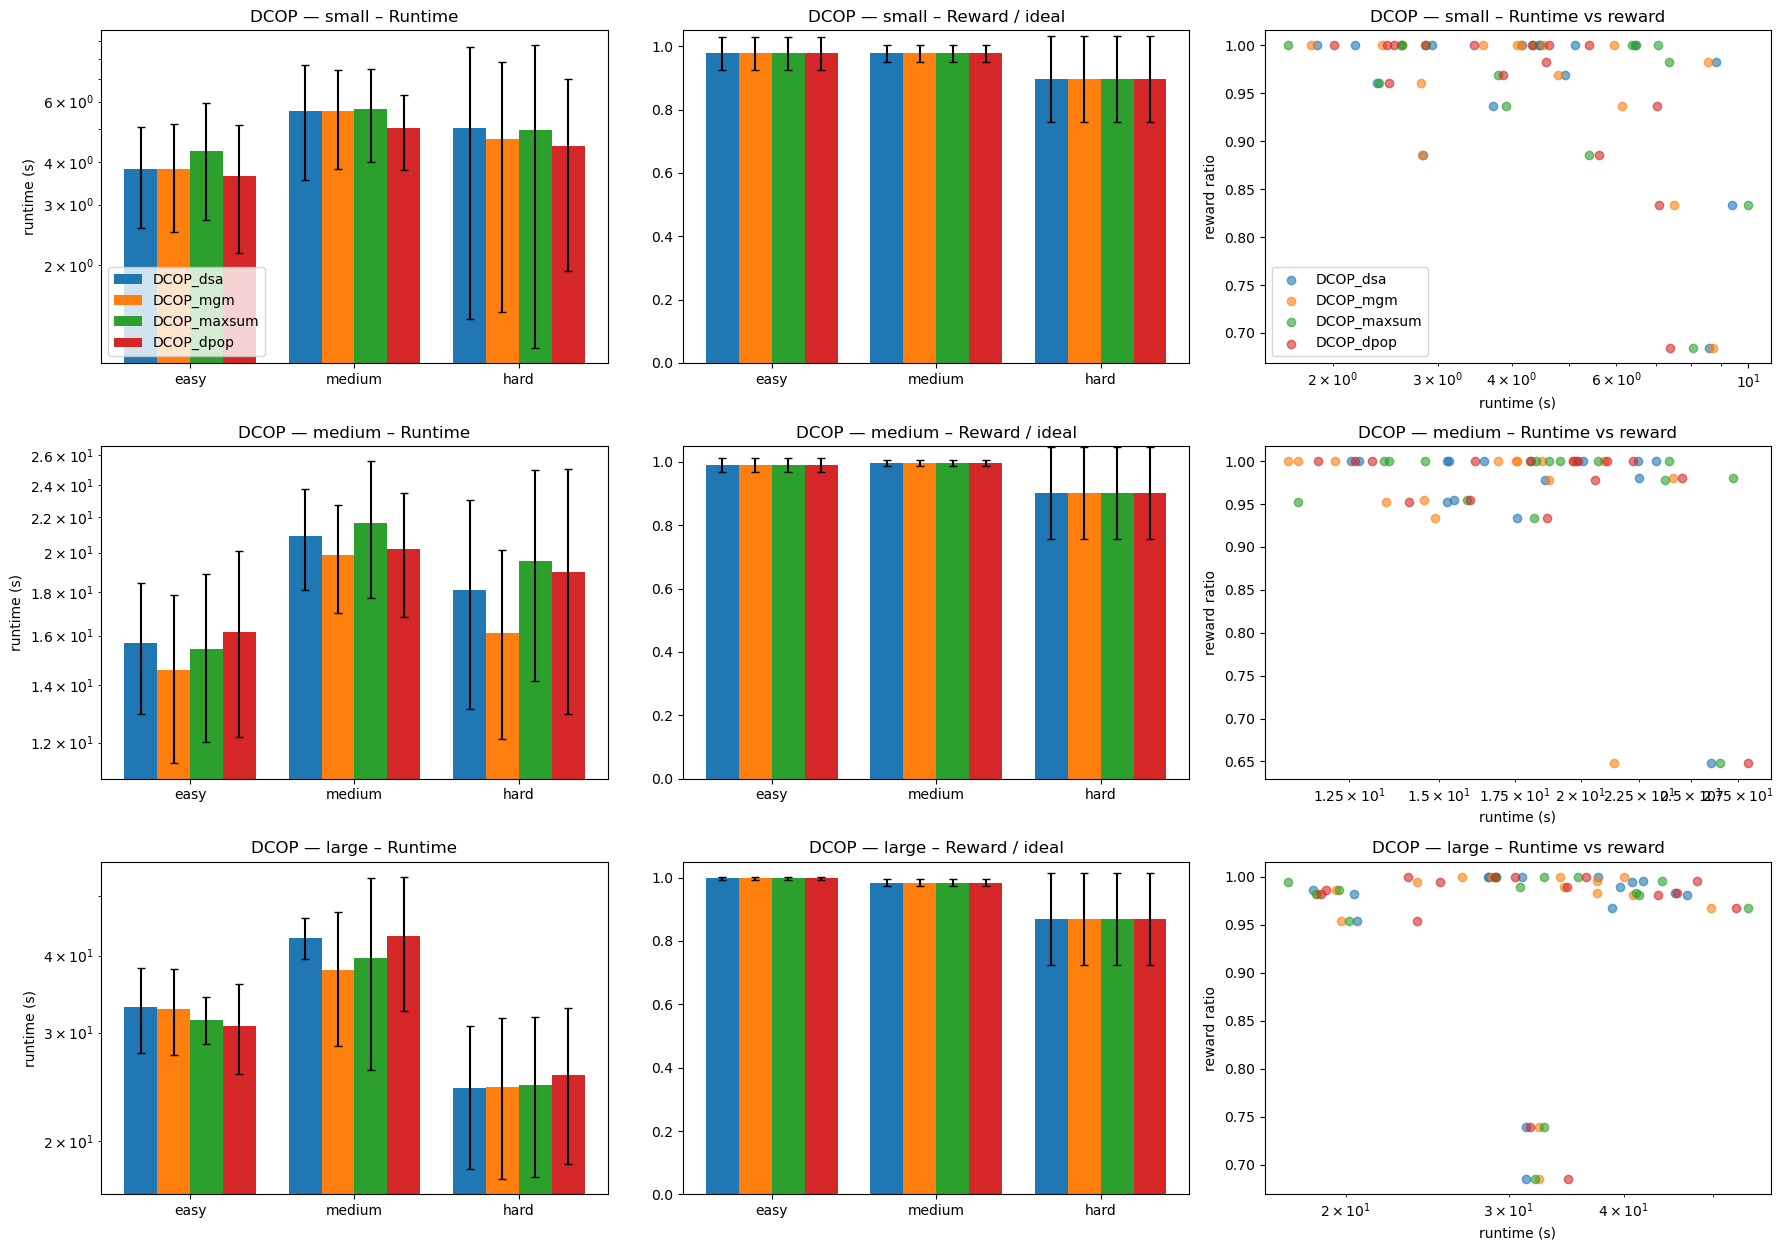

In [6]:
plot_dcop()

#### Analyse comparative : DSA vs MGM vs MAXSUM vs DPOP


### Auction

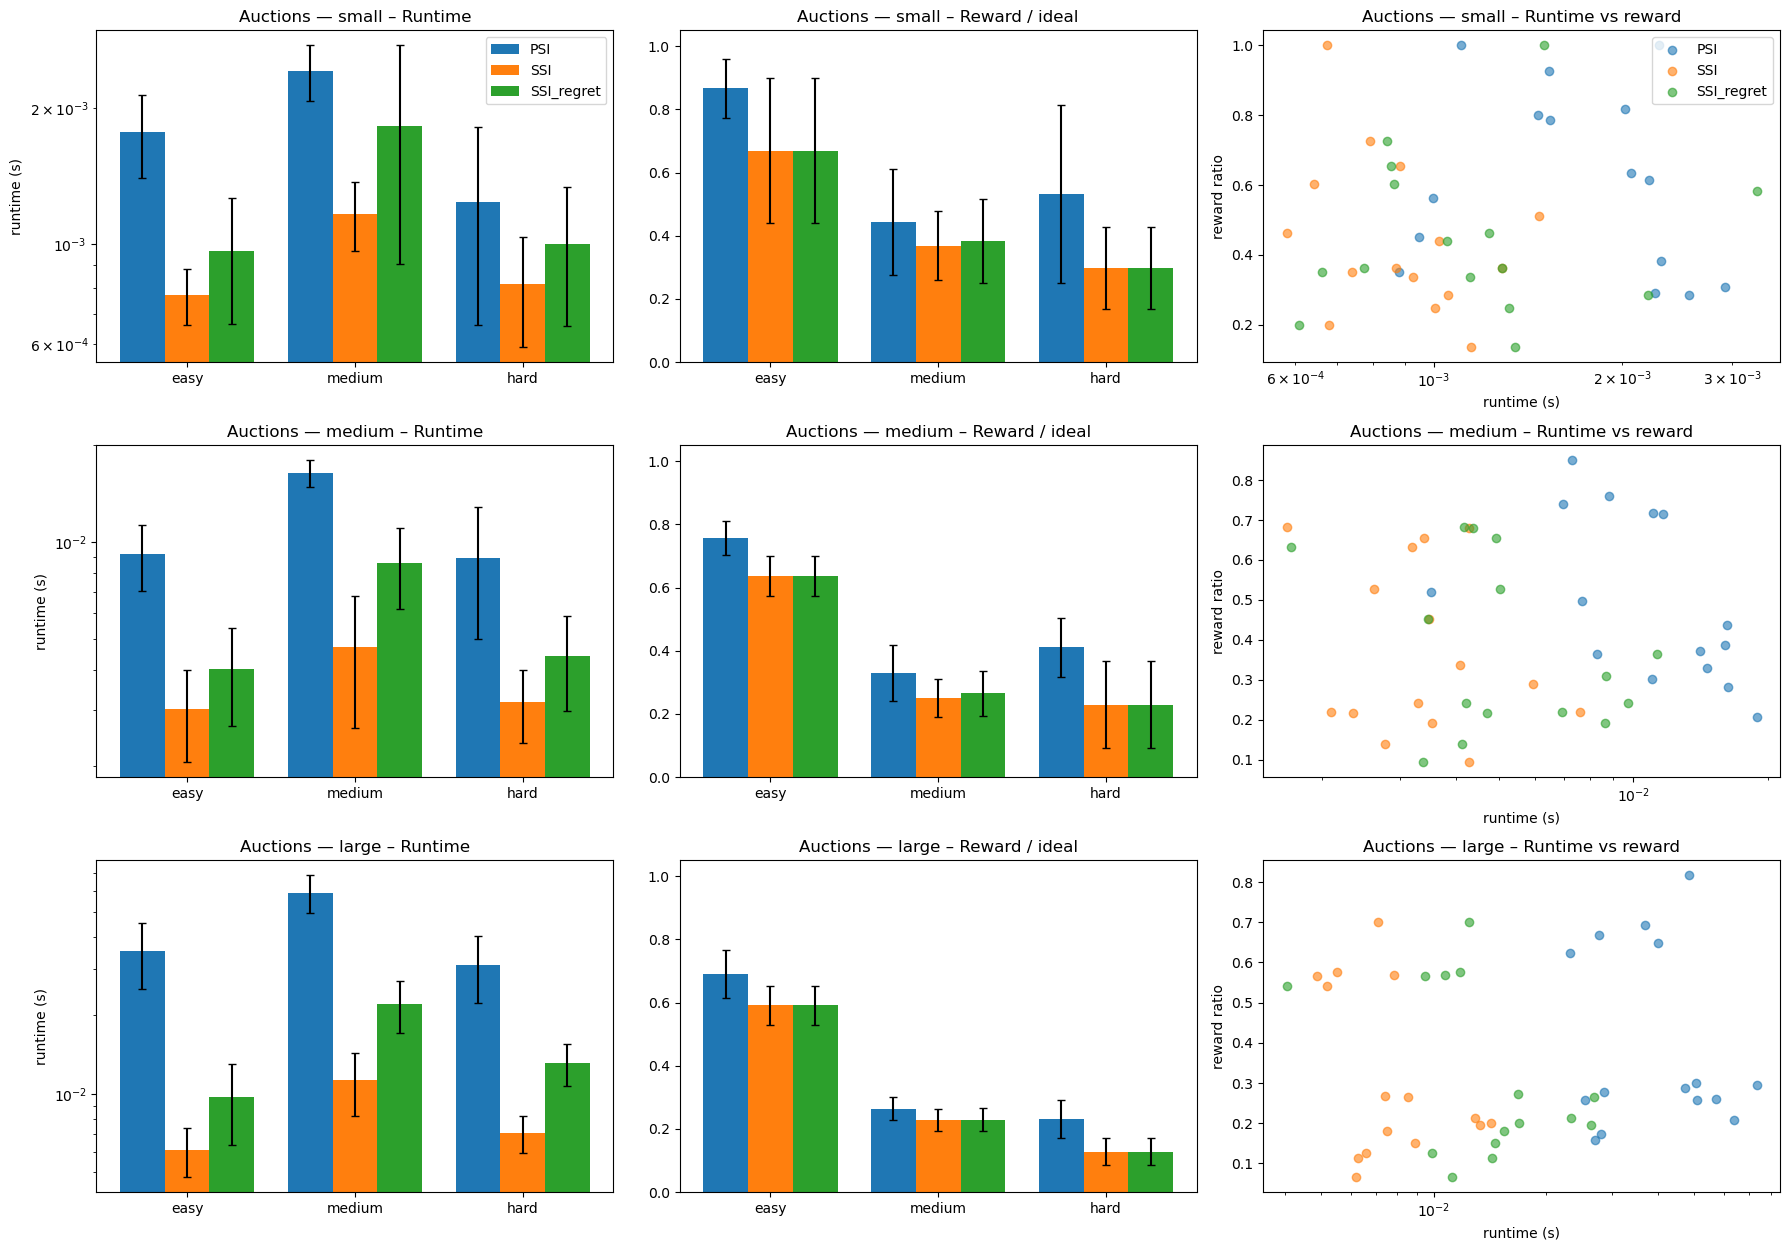

In [5]:
plot_auctions()

#### Analyse comparative : PSI vs SSI vs SSI-Regret

Sur des instances easy, les trois méthodes (PSI, SSI, SSI-Regret) atteignent des performances quasi optimales, vu que les conflits sont rares.

Lorsque la difficulté augmente (medium), PSI surpasse systématiquement SSI et SSI-Regret en qualité de solution, grâce à une meilleure coordination globale, au prix d’un temps de calcul plus élevé.

Dans les cas hard, où la faisabilité devient dominante , l’écart de qualité se réduit fortement et SSI apparaît comme un bon compromis rapidité / performance.
Enfin, SSI-Regret n’apporte qu’un gain marginal par rapport à SSI standard sur l’ensemble des configurations testées.

### DCOP vs Auction

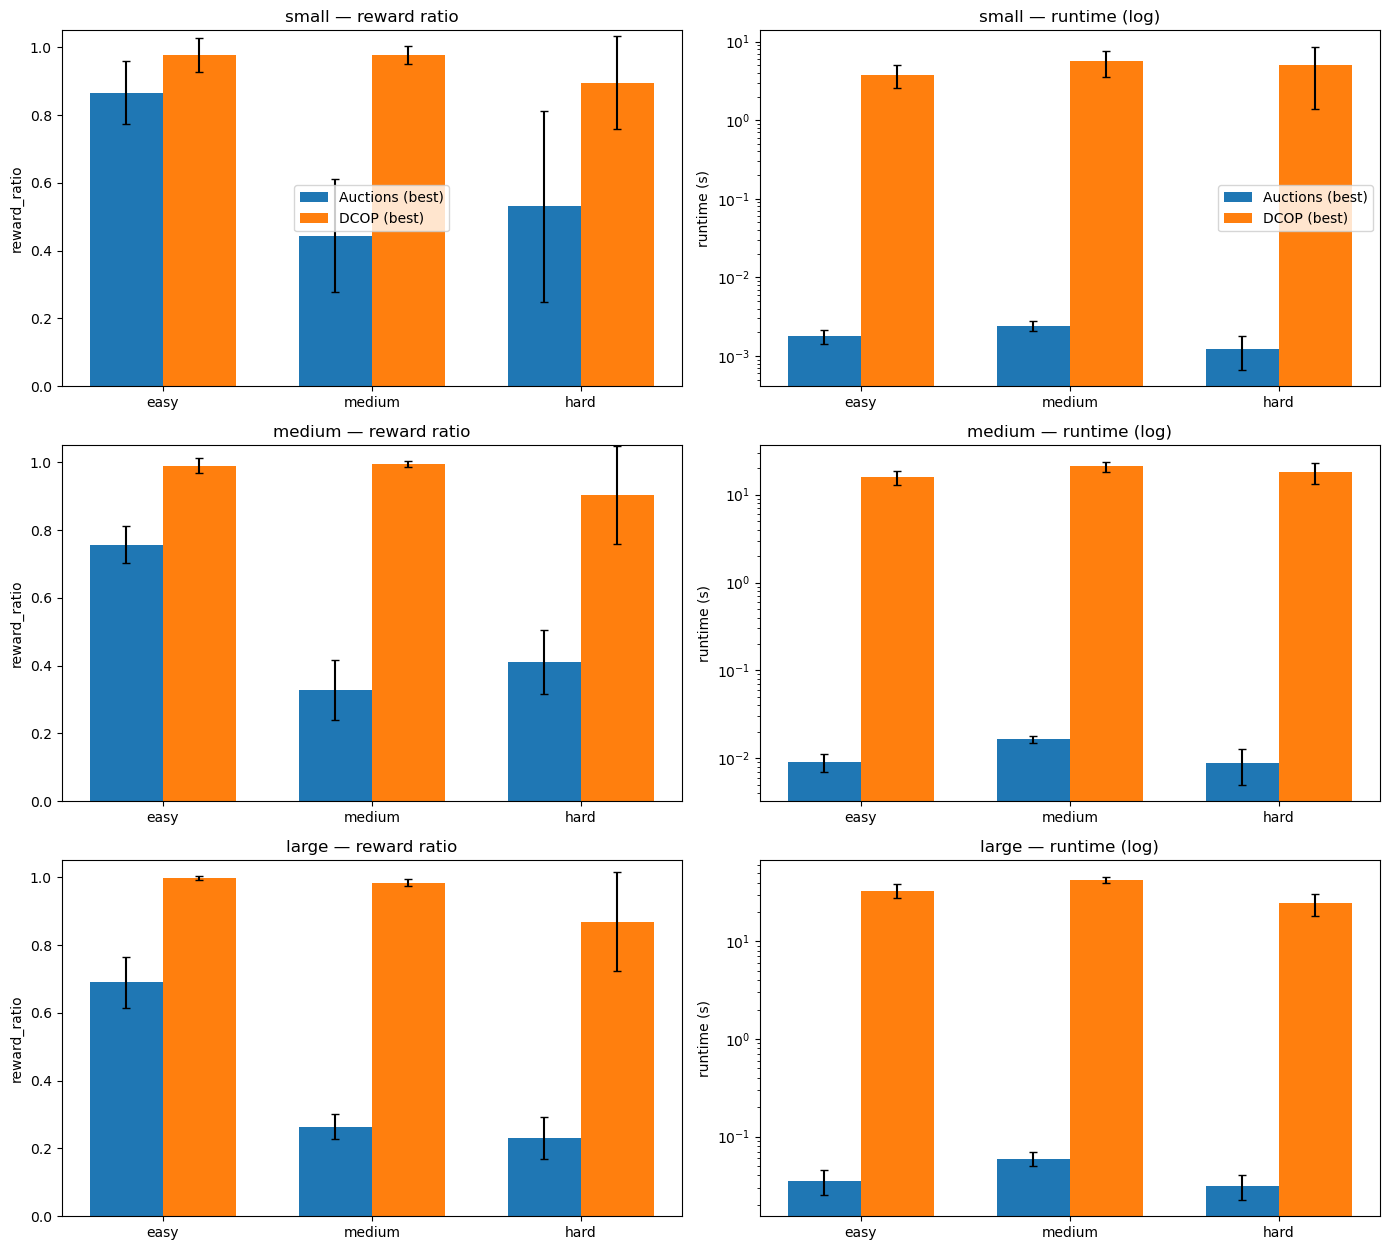

In [62]:
def read_csv_dicts(path):
    with open(path, newline="") as f:
        return list(csv.DictReader(f))

def mean_std(xs):
    xs = [float(x) for x in xs]
    if not xs:
        return float("nan"), 0.0
    m = sum(xs)/len(xs)
    if len(xs) == 1:
        return m, 0.0
    var = sum((x-m)**2 for x in xs)/(len(xs)-1)
    return m, math.sqrt(var)

def group_stats(records):
    """
    returns stats[(size,diff,algo)] = dict(runtime_mean,std, ratio_mean,std)
    """
    buckets = {}
    for r in records:
        key = (r["size"], r["difficulty"], r["algo"])
        buckets.setdefault(key, {"runtime": [], "ratio": []})
        buckets[key]["runtime"].append(float(r["runtime"]))
        buckets[key]["ratio"].append(float(r["reward_ratio"]))

    stats = {}
    for key, b in buckets.items():
        rm, rs = mean_std(b["runtime"])
        qm, qs = mean_std(b["ratio"])
        stats[key] = {
            "runtime_mean": rm, "runtime_std": rs,
            "ratio_mean": qm, "ratio_std": qs
        }
    return stats

def list_uniques(records, field):
    seen = []
    for r in records:
        v = r[field]
        if v not in seen:
            seen.append(v)
    return seen

def best_algo_per_group(stats, sizes, diffs, algos, criterion="ratio_mean"):
    """
    best[(size,diff)] = (algo, metrics_dict)
    """
    best = {}
    for size in sizes:
        for diff in diffs:
            best_key = None
            best_val = float("-inf")
            for algo in algos:
                m = stats.get((size, diff, algo))
                if not m:
                    continue
                val = m[criterion]
                if val > best_val:
                    best_val = val
                    best_key = (algo, m)
            best[(size, diff)] = best_key  # can be None
    return best

def compare_dcop_vs_auctions(
    auctions_csv="results_auctions.csv",
    dcop_csv="results_dcop.csv",
    criterion="ratio_mean",
):
    recA = read_csv_dicts(auctions_csv)
    recD = read_csv_dicts(dcop_csv)

    sizes = list_uniques(recA, "size")  # assume same ordering
    diffs = list_uniques(recA, "difficulty")

    algosA = list_uniques(recA, "algo")
    algosD = list_uniques(recD, "algo")

    statsA = group_stats(recA)
    statsD = group_stats(recD)

    bestA = best_algo_per_group(statsA, sizes, diffs, algosA, criterion=criterion)
    bestD = best_algo_per_group(statsD, sizes, diffs, algosD, criterion=criterion)

    # ---- PLOT 1: Reward ratio best vs best (bars) ----
    fig, axes = plt.subplots(nrows=len(sizes), ncols=2, figsize=(14, 4.2*len(sizes)))
    if len(sizes) == 1:
        axes = np.array([axes])

    for row, size in enumerate(sizes):
        x = np.arange(len(diffs))
        w = 0.35

        # Reward ratio
        ax = axes[row, 0]
        a_means, a_stds, d_means, d_stds = [], [], [], []
        a_labels, d_labels = [], []

        for diff in diffs:
            ba = bestA[(size, diff)]
            bd = bestD[(size, diff)]
            if ba is None:
                a_means.append(np.nan); a_stds.append(0.0); a_labels.append("—")
            else:
                a_labels.append(ba[0]); a_means.append(ba[1]["ratio_mean"]); a_stds.append(ba[1]["ratio_std"])
            if bd is None:
                d_means.append(np.nan); d_stds.append(0.0); d_labels.append("—")
            else:
                d_labels.append(bd[0]); d_means.append(bd[1]["ratio_mean"]); d_stds.append(bd[1]["ratio_std"])

        ax.bar(x - w/2, a_means, width=w, yerr=a_stds, capsize=3, label="Auctions (best)")
        ax.bar(x + w/2, d_means, width=w, yerr=d_stds, capsize=3, label="DCOP (best)")
        ax.set_xticks(x); ax.set_xticklabels(diffs)
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{size} — reward ratio")
        ax.set_ylabel("reward_ratio")

        # Runtime (log)
        ax = axes[row, 1]
        a_r_means, a_r_stds, d_r_means, d_r_stds = [], [], [], []
        for diff in diffs:
            ba = bestA[(size, diff)]
            bd = bestD[(size, diff)]
            if ba is None:
                a_r_means.append(np.nan); a_r_stds.append(0.0)
            else:
                a_r_means.append(ba[1]["runtime_mean"]); a_r_stds.append(ba[1]["runtime_std"])
            if bd is None:
                d_r_means.append(np.nan); d_r_stds.append(0.0)
            else:
                d_r_means.append(bd[1]["runtime_mean"]); d_r_stds.append(bd[1]["runtime_std"])

        ax.bar(x - w/2, a_r_means, width=w, yerr=a_r_stds, capsize=3, label="Auctions (best)")
        ax.bar(x + w/2, d_r_means, width=w, yerr=d_r_stds, capsize=3, label="DCOP (best)")
        ax.set_yscale("log")
        ax.set_xticks(x); ax.set_xticklabels(diffs)
        ax.set_title(f"{size} — runtime (log)")
        ax.set_ylabel("runtime (s)")

        if row == 0:
            axes[row, 0].legend()
            axes[row, 1].legend()

        # afficher quel algo a gagné dans la console
        # print(f"\n=== {size} ===")
        # for i, diff in enumerate(diffs):
        #     print(f"{diff:>6} | Auctions best: {a_labels[i]:>12}  ratio={a_means[i]:.3f}  rt={a_r_means[i]:.4g}s"
        #           f" | DCOP best: {d_labels[i]:>12}  ratio={d_means[i]:.3f}  rt={d_r_means[i]:.4g}s")

    plt.tight_layout()
    plt.show()

compare_dcop_vs_auctions()

#### Analyse comparative : DCOP vs Auctions (Approche optimiste)
Pour chaque couple (taille du problème, difficulté) :
- Auctions : on retient le meilleur algorithme d’enchère (PSI / SSI / SSI-regret) selon le reward ratio moyen.
- DCOP : on retient le meilleur algorithme DCOP (DSA / MGM / Max-Sum / DPOP) selon le reward ratio moyen.
- On compare ensuite :
	- la qualité de solution (reward ratio),
	- le temps de calcul (runtime, échelle logarithmique).

Cette approche met en évidence le potentiel maximal de chaque famille d’approches.

1. **Qualité** : Les méthodes DCOP atteignent presque systématiquement un reward ratio proche de 1, indépendamment de la taille ou de la difficulté des instances.
À l’inverse, même en configuration best-of, les Auctions restent en dessous de l’optimum et leur qualité se dégrade lorsque la difficulté augmente, ce qui confirme la supériorité des DCOP sur les instances medium et hard.

2. **Runtime** : Les Auctions présentent des temps de calcul extrêmement faibles, de l’ordre de la milliseconde, et restent stables lorsque la taille et la difficulté des instances augmentent.
À l’inverse, les DCOP affichent des temps de calcul nettement plus élevés, croissant rapidement avec la taille du problème, ce qui les rend moins adaptés aux contextes où la contrainte temporelle est forte.

Les Auctions utilisent des heuristiques locales et séquentielles, offrant une grande rapidité d’exécution au prix d’un regret global non nul.
À l’inverse, les DCOP explorent l’espace de décision de façon distribuée et systématique, ce qui permet d’atteindre une qualité quasi optimale mais au coût d’une complexité computationnelle plus élevée.

## 5 - Conclusion

## Références

[1] Gauthier Picard.  
    **Auction-based and Distributed Optimization Approaches for Scheduling
    Observations in Satellite Constellations with Exclusive Orbit Portions**.  
    ONERA / Université de Toulouse, 2014.

[2] Sven Koenig, Xiaoming Zheng, Craig Tovey, Philip Kilby,  
    Vangelis Markakis, Richard Borie, Pinar Keskinocak.  
    **Agent Coordination with Regret Clearing**.  
    *Proceedings of the AAAI Conference on Artificial Intelligence (AAAI)*, 2008.  